# Theoretical validations

Each section integrates timelike geodesics with Relatipy and compares them with formulas quoted literally from the literature (equation numbers given).

Conventions used throughout:

* units $G=c=M=1$, Boyer–Lindquist coordinates $(t,r,\theta,\phi)$
* spin $\chi=J/M^2$, $0\le\chi<1$, the `spin=` argument of `rp.Kerr`; papers that use the spin length $a=J/M$ are quoted with $a=\chi M$
* $\Delta$ ([Bini, Geralico & Jantzen 2016](https://doi.org/10.1103/PhysRevD.94.064066), eq. 2):

$$\Delta=r^2-2Mr+\chi^2M^2$$

* horizons ([Mummery & Balbus 2022](https://doi.org/10.1103/PhysRevLett.129.161101), eq. 25):

$$r_\pm=M\pm\sqrt{M^2-\chi^2M^2}$$

* Relatipy takes coordinate-time velocities (`vR`, `vPhi`), so a four-velocity enters as $v^i=u^i/u^t$

In [1]:
!pip install -Uq relatipy kerrgeopy pygro setuptools cython

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


In [1]:
import dataclasses
import logging
import time
from functools import partial
from pathlib import Path

import relatipy as rp
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
from astropy.table import Table
from scipy.integrate import quad
from scipy.optimize import brentq
import mpmath as mp

import kerrgeopy as kg
import pygro

Shared helpers:

* `time_scale`: time unit $GM/c^3$, to convert times and velocities given in units of $M$
* `equatorial_orbit`: builds an orbit on $\theta=\pi/2$ from $(u^t,u^r,u^\phi)$, converting to $v^i=u^i/u^t$
* `upward_crossings`: instants where a sampled quantity crosses zero upwards (pericentres, oscillation midpoints). A cubic fit of $y(g)$ through the four samples around each sign change; a linear interpolation limits the error to $\sim10^{-5}$
* `hermite_pericentres`: pericentres from cubic Hermite interpolants that use the stored velocities (see section 3)
* `glue_panels`: panels that share an axis touch, without a gap; call it after plotting. It freezes the layout and moves the axes by hand, and hides a tick label that would cross a joint
* `stacked_blocks`: single-column figure with blocks of panels stacked vertically, (a) on top of (b); panels share $x$ inside each block
* `save_paper_figure`: saves pdf and png of a figure into the preprint folder `figures/<section>/` (skipped if that folder is not next to this repository)

In [2]:
def time_scale(bh):
    """Time unit G M / c^3 of the native geometric convention."""
    return (bh.r_g / const.c).to(u.s)


def equatorial_orbit(bh, r, u_t, u_r, u_phi):
    """Orbit at radius r [M] on the equator, from its four-velocity (u^t, u^r, u^phi) in units of M."""
    return bh.orbit(
        R=r * bh.r_g,
        Theta=90 * u.deg,
        Phi=0 * u.rad,
        vR=u_r / u_t * bh.r_g / time_scale(bh),
        vPhi=u_phi / u_t * u.rad / time_scale(bh),
    )


def upward_crossings(g, y):
    """y where g changes sign from negative to positive, from a cubic fit of y(g) over the four samples around each change."""
    steps = np.where((g[:-1] < 0) & (g[1:] >= 0))[0]
    steps = steps[(steps > 0) & (steps < g.size - 2)]
    return np.array([np.polyval(np.polyfit(g[i-1:i+3], y[i-1:i+3], 3), 0) for i in steps])


def hermite_pericentres(tau, r, u_r, phi, u_phi):
    """Unwrapped phi [rad] at every pericentre, from cubic Hermite interpolants of r(tau) and phi(tau)."""
    phi = np.unwrap(phi)
    phases = []
    for i in np.where((u_r[:-1] < 0) & (u_r[1:] >= 0))[0]:
        h = tau[i+1] - tau[i]
        # r(s) on s in [0, 1]: cubic through r and h*u^r at both ends
        c3 = 2*r[i] - 2*r[i+1] + h*(u_r[i] + u_r[i+1])
        c2 = -3*r[i] + 3*r[i+1] - h*(2*u_r[i] + u_r[i+1])
        roots = np.roots([3*c3, 2*c2, h*u_r[i]])
        s = next(x.real for x in roots
                 if abs(x.imag) < 1e-12 and -1e-9 <= x.real <= 1 + 1e-9 and 6*c3*x.real + 2*c2 > 0)
        phases.append(
            (2*s**3 - 3*s**2 + 1) * phi[i]
            + (s**3 - 2*s**2 + s) * h * u_phi[i]
            + (-2*s**3 + 3*s**2) * phi[i+1]
            + (s**3 - s**2) * h * u_phi[i+1]
        )
    return np.array(phases)


def glue_panels(fig, groups=None):
    """Make panels that share an axis touch. Call after plotting, before saving.

    groups: lists of axes stacked top to bottom that must touch; by default, every column.
    """
    fig.align_ylabels()
    fig.canvas.draw()                  # let the layout engine place labels and legends
    fig.set_layout_engine("none")      # freeze it, then close the gaps by hand
    if groups is None:
        columns = {}
        for ax in fig.axes:
            spec = ax.get_subplotspec()
            if spec is not None and ax.get_visible():
                columns.setdefault(spec.colspan.start, []).append(ax)
        groups = list(columns.values())
    groups = [sorted(group, key=lambda ax: -ax.get_position().y1) for group in groups]
    for axes in groups:
        boxes = [ax.get_position() for ax in axes]
        top, bottom = boxes[0].y1, boxes[-1].y0
        scale = (top - bottom) / sum(box.height for box in boxes)
        for ax, box in zip(axes, boxes):
            height = box.height * scale
            ax.set_position([box.x0, top - height, box.width, height])
            top -= height
    fig.canvas.draw()
    # A tick label that sticks out above a lower panel would collide at the joint
    for axes in groups:
        for ax in axes[1:]:
            edge = ax.get_window_extent().y1
            for label in ax.get_yticklabels():
                if label.get_visible() and label.get_window_extent().y1 > edge + 0.5:
                    label.set_visible(False)


def stacked_blocks(height, ratios, n_blocks=2, gap=0.03):
    """Single-column figure with n_blocks vertical blocks of panels (top to bottom) that share x inside each block."""
    n = len(ratios)
    fig, axes = new_figure(
        PAPER_WIDTH, height=height, nrows=n_blocks * (n + 1) - 1,
        height_ratios=([*ratios, gap] * n_blocks)[:-1])
    blocks = [list(axes[b * (n + 1):b * (n + 1) + n]) for b in range(n_blocks)]
    for spacer in axes[n::n + 1]:
        spacer.set_visible(False)
    for block in blocks:
        for ax in block[:-1]:
            ax.sharex(block[-1])
            ax.tick_params(labelbottom=False)
    return fig, blocks


def save_paper_figure(fig, section, name):
    """Save pdf + png to the preprint figures folder of a section, when that folder is reachable."""
    if PAPER_FIGURES.is_dir():
        (PAPER_FIGURES / section).mkdir(exist_ok=True)
        rp.plotting.save_figure(fig, PAPER_FIGURES / section / name)


PAPER_FIGURES = Path("../../../thesis/preprint/figures")    # thesis repo next to relatipy; skipped if absent
PAPER_WIDTH = rp.plotting.TARGETS["aanda"].width_mm    # A&A column [mm]
# A&A format: Times text, STIX math; axis labels 9 pt, ticks 8 pt, legends and annotations 7.5 pt
STYLE = rp.plotting.DEFAULT_STYLE.replace(
    target=dataclasses.replace(rp.plotting.TARGETS["aanda"], label_size=9.0, tick_size=8.0, small_size=7.5),
    font=None, math_font=None,
    frame=dataclasses.replace(rp.plotting.DEFAULT_STYLE.frame, minor_tick_length=2.0),
)
TAG_SIZE = STYLE.target.label_size    # panel labels (a), (b), ... at the axis-label size
new_figure = partial(rp.plotting.new_figure, style=STYLE)
plt.rcParams.update(rp.plotting.rc_params(STYLE))    # same style also for legends and lines


COLORS = rp.plotting.DEFAULT_STYLE.trajectory_colors[1:]

Comparison codes, set up once here and reused in every section:

* [KerrGeoPy](https://doi.org/10.21105/joss.06587) (Park & Nasipak 2024): analytic bound Kerr geodesics; returns the orbital frequencies $\Omega_r,\Omega_\theta,\Omega_\phi$ in Boyer–Lindquist time in closed form (elliptic integrals)
* [PyGRO](https://doi.org/10.1051/0004-6361/202554300) (Della Monica 2025): generic geodesic integrator built from a symbolic metric. Kerr in Boyer–Lindquist coordinates written as in its documentation example (`docs/source/examples/Kerr-Photons.ipynb`): integrator `rkf78`, stop at the horizon ($\Delta>10^{-4}$)

PyGRO details:

* it derives and compiles the geodesic equations for each value of $\chi$ (~20 s, needs a C compiler, `setuptools` and `cython`): `pygro_engine(chi)` keeps them
* `pygro_solve` starts PyGRO from the same initial state as a Relatipy orbit: Boyer–Lindquist position and four-velocity in units of $M$
* its tolerance is set with `accuracy_goal` and `precision_goal`: `atol = rtol = 10**-goal`
* extra keyword arguments of `pygro_solve` go to PyGRO's integrator, e.g. `hmax`, the largest proper-time step

In [3]:
logging.getLogger().setLevel(logging.WARNING)    # PyGRO logs at INFO level by default

_pygro_engines = {}


def pygro_engine(chi):
    """PyGRO Kerr metric (M = 1, a = chi) and geodesic engine, compiled once per spin."""
    if chi not in _pygro_engines:
        metric = pygro.Metric(
            name="Kerr spacetime",
            coordinates=["t", "r", "theta", "phi"],
            line_element=(
                "-(1-2*M*r/(Sigma(r,theta)))*dt**2"
                "+Sigma(r,theta)/Delta(r)*dr**2"
                "+Sigma(r,theta)*dtheta**2"
                "+(r**2+a**2+2*M*r*a**2/Sigma(r,theta)*sin(theta)**2)*sin(theta)**2*dphi**2"
                "-4*M*r*a*sin(theta)**2/Sigma(r,theta)*dt*dphi"
            ),
            transform=[
                "t",
                "sqrt(r**2+a**2)*sin(theta)*cos(phi)",
                "sqrt(r**2+a**2)*sin(theta)*sin(phi)",
                "r*cos(theta)",
            ],
            Sigma="r**2+a**2*cos(theta)**2",
            Delta="r**2-2*M*r+a**2",
            M=1,
            a=chi,
        )
        engine = pygro.GeodesicEngine(metric, backend="autowrap", integrator="rkf78")
        engine.set_stopping_criterion("r**2-2*M*r+a**2 > 1e-4", "horizon")
        _pygro_engines[chi] = engine
    return _pygro_engines[chi]


def pygro_solve(bh, orbit, tau_end, goal=10, **options):
    """PyGRO geodesic from the initial state of a relatipy orbit, up to proper time tau_end [M].

    options: passed to the PyGRO integrator (e.g. hmax, largest step [M]).
    """
    T0 = time_scale(bh)
    engine = pygro_engine(bh.spin)
    geo = pygro.Geodesic("time-like", engine, verbose=False)
    geo.initial_x = [
        0.0,
        (orbit.R / bh.r_g).to_value(u.one),
        orbit.Theta.to_value(u.rad),
        orbit.Phi.to_value(u.rad),
    ]
    geo.initial_u = [
        float(orbit.ut.value),
        (orbit.uR / const.c).to_value(u.one),
        (orbit.uTheta * T0).to_value(u.rad),
        (orbit.uPhi * T0).to_value(u.rad),
    ]
    first_step = min(1.0, options.get("hmax", 1.0))    # PyGRO does not cap its first step with hmax
    engine.integrate(geo, tau_end, first_step, accuracy_goal=goal, precision_goal=goal, **options)
    return geo


pygro_engine(0.9);    # compiled now; used in sections 1.4 and 3

## 1. Innermost stable circular orbit (ISCO)

Angular velocity of circular equatorial orbits ([Teukolsky 2015](https://doi.org/10.1088/0264-9381/32/12/124006), eq. 9.1):

$$\Omega_{\rm circular}=\pm\frac{M^{1/2}}{r^{3/2}\pm\chi M\,M^{1/2}}$$

* "the upper and lower signs refer to prograde and retrograde orbits" (same paper)

ISCO radius $r_I$ ([Mummery & Balbus 2022](https://doi.org/10.1103/PhysRevLett.129.161101), eq. 6):

$$r_I^2=6Mr_I-8\chi M\sqrt{Mr_I}+3\chi^2M^2$$

* retrograde orbits: same equation with the spin taken negative (same paper; a spin of $-1$ gives $r_I=9M$)
* `r_isco` solves eq. 6 for the root above the horizon $r_+$, with spin $+\chi$ (prograde) or $-\chi$ (retrograde)

### 1.1. ISCO radius

`bh.r_isco_prograde` and `bh.r_isco_retrograde` against the root of eq. 6, sweeping $\chi$. The difference is plotted in units of machine epsilon $\epsilon_{\rm mach}$.

In [4]:
from scipy.optimize import brentq


def r_isco(chi, sign):
    """ISCO radius [M]: root of Mummery & Balbus 2022, eq. 6, with spin = sign * chi (M = 1)."""
    spin = sign * chi
    r_plus = 1 + np.sqrt(1 - chi**2)
    return brentq(lambda r_I: r_I**2 - (6*r_I - 8*spin*np.sqrt(r_I) + 3*spin**2), r_plus, 10,
                  xtol=1e-15, rtol=4 * np.finfo(float).eps)


branches = {+1: "prograde", -1: "retrograde"}
chi_grid = np.linspace(0, 0.999, 200)
holes = [rp.Kerr(mass=4.3e6*u.Msun, spin=chi) for chi in chi_grid]

isco = {}
for sign, name in branches.items():
    library = np.array([(getattr(h, f"r_isco_{name}") / h.r_g).to_value(u.one) for h in holes])
    formula = np.array([r_isco(chi, sign) for chi in chi_grid])
    isco[sign] = dict(
        library=library,
        formula=formula,
        rel_diff=library / formula - 1,
    )

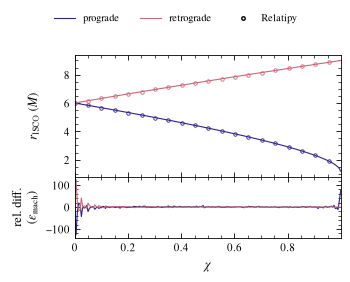

In [5]:
fig, (ax_r, ax_d) = new_figure(
    PAPER_WIDTH, height=70, nrows=2, sharex=True, height_ratios=(2, 1))

every = slice(None, None, 10)
for c, (sign, name) in zip(COLORS, branches.items()):
    ax_r.plot(chi_grid, isco[sign]["formula"], color=c, label=name)
    ax_r.plot(chi_grid[every], isco[sign]["library"][every], "o", color=c, ms=2.5, mfc="none", mew=0.6)
    ax_d.plot(chi_grid, isco[sign]["rel_diff"] / np.finfo(float).eps, color=c, lw=0.8)

ax_r.plot([], [], "o", color="k", ms=2.5, mfc="none", label="Relatipy")
ax_r.set(ylabel=r"$r_{\rm ISCO}$ ($M$)")
ax_d.set(xlabel=r"$\chi$", ylabel="rel. diff.\n" + r"($\epsilon_{\rm mach}$)",
         xlim=(chi_grid.min(), chi_grid.max()))
fig.legend(*ax_r.get_legend_handles_labels(), loc="outside upper center", ncols=3,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'isco', 'isco-radius')
plt.show()

Largest difference over the $\chi$ sweep, in units of $\epsilon_{\rm mach}$ (quoted in the paper):

In [6]:
Table(rows=[
    dict(
        branch=name,
        max_rel_diff_eps=np.abs(isco[sign]["rel_diff"]).max() / np.finfo(float).eps,
    )
    for sign, name in branches.items()
])

branch,max_rel_diff_eps
str10,float64
prograde,127.0
retrograde,125.0


### 1.2. Radial epicyclic frequency

Coordinate-time Keplerian and radial epicyclic frequencies of circular equatorial orbits ([Török & Stuchlík 2005](https://arxiv.org/abs/astro-ph/0502127), Sect. 2, eqs. 1, 2 and 4):

$$\Omega_{\rm K}=\left(\frac{GM_0}{r_G^{3}}\right)^{1/2}\left(x^{3/2}+a\right)^{-1}$$

$$\omega_r^2=\alpha_r\,\Omega_{\rm K}^2,\qquad \alpha_r(x,a)\equiv1-6x^{-1}+8a\,x^{-3/2}-3a^2x^{-2}$$

* $x=r/M$ (eq. 6), $a$ the dimensionless spin ($\chi$ here); frequencies seen from infinity, i.e. coordinate time
* $\Omega_{\rm K}$ is the circular frequency $\Omega_\phi$ (Teukolsky eq. 9.1); the paper writes $\Omega_r$ as $\omega_r$
* retrograde orbits: $a\to-\chi$, as in the circular frequency
* $\Omega_r=0$ where $\alpha_r=0$, the ISCO condition of section 1 (Mummery & Balbus 2022, eqs. 5–6)

Measurement, for $\chi=0.9$ and both branches:

* start at $r(1+\delta)$ with $d\phi/dt=\Omega_{\rm circular}(r)$ (Teukolsky eq. 9.1) and $u^r=0$
* $\delta=10^{-4}(1-r_I/r)$: the finite amplitude shifts the frequency most near the ISCO, so $\delta$ shrinks there
* $\Omega_r$ from the coordinate times $t_k$ at which $r$ crosses its mid value $\bar r=(r_{\max}+r_{\min})/2$ upwards, over $N$ crossings:

$$\Omega_r^{\rm int}=\frac{2\pi\,(N-1)}{t_N-t_1}$$

* compared with eq. 2 at $r=\bar r$, which removes the first-order shift of the oscillation centre
* `max_step` set to $T_r/400$ so every oscillation is well sampled

In [5]:
def circular_frequency(r, chi, sign):
    """d(phi)/dt [1/M] of a circular equatorial orbit: Teukolsky 2015, eq. 9.1 (M = 1)."""
    return sign / (r**1.5 + sign * chi)


def epicyclic_frequencies(r, chi, sign):
    """(Omega_r, Omega_phi) [1/M]: Torok & Stuchlik 2005, eqs. 1, 2 and 4 with x = r (M = 1) and a = sign * chi."""
    spin = sign * chi
    omega_phi = 1 / (r**1.5 + spin)
    alpha_r = 1 - 6/r + 8*spin * r**-1.5 - 3*spin**2 / r**2
    return np.sqrt(alpha_r) * omega_phi, omega_phi


def measure_epicyclic(bh, r, sign, n_periods=10):
    """Integrated and exact radial frequency [1/M] around radius r [M]."""
    T0 = time_scale(bh)
    delta = 1e-4 * (1 - r_isco(bh.spin, sign) / r)
    T_r = 2*np.pi / epicyclic_frequencies(r, bh.spin, sign)[0]
    orbit = bh.orbit(
        R=r * (1 + delta) * bh.r_g,
        Theta=90 * u.deg,
        Phi=0 * u.rad,
        vPhi=circular_frequency(r, bh.spin, sign) * u.rad / T0,
    )
    sol = orbit.solve(
        tau_span=(0 * T0, n_periods * T_r * T0),
        method="projection_radau",
        max_step=T_r / 400 * T0,
    )

    t = (sol.t / T0).to_value(u.one)
    R = (sol.R / bh.r_g).to_value(u.one)
    r_mid = 0.5 * (R.max() + R.min())
    t_cross = upward_crossings(R - r_mid, t)

    measured = 2*np.pi * (t_cross.size - 1) / (t_cross[-1] - t_cross[0])
    omega_r, omega_phi = epicyclic_frequencies(r_mid, bh.spin, sign)
    return dict(
        x=r_mid / r_isco(bh.spin, sign),
        ratio=measured / omega_phi,
        rel_error=abs(measured / omega_r - 1),
    )


bh = rp.Kerr(mass=4.3e6*u.Msun, spin=0.9)
x_grid = np.geomspace(1.01, 30, 25)
epicyclic = {
    sign: Table(rows=[measure_epicyclic(bh, x * r_isco(bh.spin, sign), sign) for x in x_grid])
    for sign in branches
}

/tmp/ipykernel_1285930/1592343969.py:11: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(alpha_r) * omega_phi, omega_phi


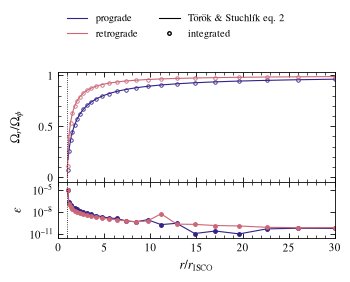

In [6]:
fig, (ax_w, ax_e) = new_figure(
    PAPER_WIDTH, height=70, nrows=2, sharex=True, height_ratios=(2, 1))

x_fine = np.linspace(1, x_grid.max(), 400)
for c, (sign, name) in zip(COLORS, branches.items()):
    omega_r, omega_phi = epicyclic_frequencies(x_fine * r_isco(bh.spin, sign), bh.spin, sign)
    exact = omega_r / omega_phi
    ax_w.plot(x_fine, exact, color=c, label=name)
    ax_w.plot(epicyclic[sign]["x"], epicyclic[sign]["ratio"], "o", color=c, ms=2.5, mfc="none", mew=0.6)
    ax_e.plot(epicyclic[sign]["x"], epicyclic[sign]["rel_error"], "o-", color=c, ms=2.5, lw=0.8)

ax_w.plot([], [], color="k", label="Török & Stuchlík eq. 2")
ax_w.plot([], [], "o", color="k", ms=2.5, mfc="none", label="integrated")
ax_w.set(ylabel=r"$\Omega_r/\Omega_\phi$")
ax_e.set(xlabel=r"$r/r_{\rm ISCO}$", ylabel=r"$\varepsilon$", yscale="log",
         xlim=(0, x_grid.max()), ylim=(3e-12, 1e-4), yticks=[1e-11, 1e-8, 1e-5])
for ax in (ax_w, ax_e):
    ax.axvline(1, color="k", ls=":", lw=0.6)    # ISCO
fig.legend(*ax_w.get_legend_handles_labels(), loc="outside upper center", ncols=2,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'isco', 'epicyclic-frequency')
plt.show()

Smallest and largest $\varepsilon$ over the radii, and $r/r_{\rm ISCO}$ of the largest (quoted in the paper):

In [7]:
Table(rows=[
    dict(
        branch=name,
        min_rel_error=epicyclic[sign]["rel_error"].min(),
        max_rel_error=epicyclic[sign]["rel_error"].max(),
        x_at_max=epicyclic[sign]["x"][np.argmax(epicyclic[sign]["rel_error"])],
    )
    for sign, name in branches.items()
])

branch,min_rel_error,max_rel_error,x_at_max
str10,float64,float64,float64
prograde,9.783507337601804e-12,1.0341028222837778e-05,1.0102028425022285
retrograde,6.772382654673947e-11,9.137509396461851e-06,1.0102011782040075


### 1.3. Plunge from the ISCO

A particle with exactly the ISCO energy and angular momentum that starts just inside the ISCO plunges along a closed-form path ([Mummery & Balbus 2022](https://doi.org/10.1103/PhysRevLett.129.161101)).

Angular momentum $J$ and energy $\gamma$ at the ISCO (eqs. 7 and 8):

$$J=2\sqrt3M\left(1-\frac{2\chi M}{3\sqrt{Mr_I}}\right)$$

$$\gamma=\left(1-\frac{2M}{3r_I}\right)^{1/2}$$

* eq. 8 gives two equal forms of $\gamma$; the right-hand one is quoted, equal to the left one by eq. 6

Four-velocity along the plunge (eqs. 13 and 14):

$$U^r\equiv\frac{dr}{d\tau}=-\sqrt{\frac{2M}{3r_I}}\left(\frac{r_I}{r}-1\right)^{3/2}$$

$$U^\phi=\frac{2M\gamma\chi M+J(r-2M)}{r(r^2-2Mr+\chi^2M^2)}$$

Proper time (eq. 18), with $x=r/r_I$:

$$\tau=\sqrt{\frac{3r_I^3}{2M}}\left(3\sin^{-1}\sqrt{x}+(x-3)\sqrt{\frac{x}{1-x}}\right)$$

$U^t$ is not given there; it follows from the equatorial geodesic equation ([Bini, Geralico & Jantzen 2016](https://doi.org/10.1103/PhysRevD.94.064066), eq. 5):

$$\Delta\,r^2\frac{dt}{d\tau}=(Er^2-\chi Mx_{\rm B})(r^2+\chi^2M^2)+\Delta\,\chi M\,x_{\rm B}$$

* $x_{\rm B}=L-\chi ME$ (their $x$, text before eq. 5)
* $E=\gamma$, $L=J$
* retrograde: Mummery & Balbus take the spin negative; in this notebook's frame (spin $+\chi$) that orbit has $L\to-L$ and $U^\phi\to-U^\phi$ (Bini et al., after eq. 10)
* $\tau$ is defined up to a constant: compared as $\tau(r)-\tau(r_0)$

Start at $r_0=r_I(1-\epsilon)$ with $\epsilon=10^{-2}$ and stop at $r_+(1+10^{-2})$:

* closer starts do not work: $(U^r)^2\propto\epsilon^3$, which for $\epsilon=10^{-6}$ is $10^{-18}$, below the rounding of $E$ and $L$ ($\sim10^{-16}$)
* $\varepsilon=|\tau_{\rm int}/[\tau(r)-\tau(r_0)]-1|$ at every stored sample

In [10]:
def plunge_time(r, r_I):
    """Proper time [M] of the ISCO plunge, up to a constant: Mummery & Balbus 2022, eq. 18 (M = 1)."""
    x = r / r_I
    return np.sqrt(3 * r_I**3 / 2) * (3*np.arcsin(np.sqrt(x)) + (x - 3) * np.sqrt(x / (1 - x)))


def isco_plunge(bh, sign, eps=1e-2):
    """Plunge integrated from r_I (1 - eps) to r_+ (1 + 1e-2), against the closed form."""
    chi = bh.spin
    spin = sign * chi                      # Mummery & Balbus take the spin negative for retrograde
    r_I = r_isco(chi, sign)
    J = 2*np.sqrt(3) * (1 - 2*spin / (3*np.sqrt(r_I)))          # eq. 7
    gamma = np.sqrt(1 - 2 / (3*r_I))                         # eq. 8

    r0 = r_I * (1 - eps)
    Delta = r0**2 - 2*r0 + spin**2
    x_B = J - spin*gamma
    u_r = -np.sqrt(2 / (3*r_I)) * (r_I/r0 - 1)**1.5          # eq. 13
    u_phi = (2*gamma*spin + J*(r0 - 2)) / (r0 * Delta)          # eq. 14
    u_t = ((gamma*r0**2 - spin*x_B) * (r0**2 + spin**2) + Delta*spin*x_B) / (Delta * r0**2)   # Bini eq. 5

    r_end = (1 + np.sqrt(1 - chi**2)) * (1 + 1e-2)
    tau_end = plunge_time(r_end, r_I) - plunge_time(r0, r_I)
    sol = equatorial_orbit(bh, r0, u_t, u_r, sign * u_phi).solve(
        tau_span=(0 * time_scale(bh), tau_end * time_scale(bh)),
        method="projection_radau",
    )

    r = (sol.R / bh.r_g).to_value(u.one)[1:]
    tau = (sol.tau / time_scale(bh)).to_value(u.one)[1:]
    exact = plunge_time(r, r_I) - plunge_time(r0, r_I)
    return dict(
        status=sol.status,
        r=r,
        tau=tau,
        exact=exact,
        rel_error=np.abs(tau / exact - 1),
    )


plunge = {sign: isco_plunge(bh, sign) for sign in branches}

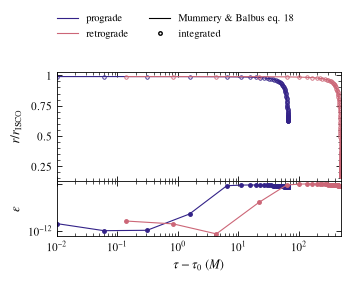

In [11]:
fig, (ax_r, ax_e) = new_figure(
    PAPER_WIDTH, height=70, nrows=2, sharex=True, height_ratios=(2, 1))

for c, (sign, name) in zip(COLORS, branches.items()):
    p = plunge[sign]
    r_I = r_isco(bh.spin, sign)
    ax_r.plot(p["exact"], p["r"] / r_I, color=c, label=name)
    ax_r.plot(p["tau"], p["r"] / r_I, "o", color=c, ms=2.5, mfc="none", mew=0.6)
    ax_e.plot(p["tau"], p["rel_error"], "o-", color=c, ms=2.5, lw=0.8)

tau_all = np.concatenate([p["tau"] for p in plunge.values()])
ax_r.plot([], [], color="k", label="Mummery & Balbus eq. 18")
ax_r.plot([], [], "o", color="k", ms=2.5, mfc="none", label="integrated")
ax_r.set(ylabel=r"$r/r_{\rm ISCO}$", xscale="log")
ax_e.set(xlabel=r"$\tau-\tau_0$ ($M$)", ylabel=r"$\varepsilon$", yscale="log",
         xlim=(tau_all.min(), tau_all.max()))
fig.legend(*ax_r.get_legend_handles_labels(), loc="outside upper center", ncols=2,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'isco', 'isco-plunge')
plt.show()

Largest $\varepsilon$ along each plunge and proper time to $r_+(1+10^{-2})$ (quoted in the paper):

In [12]:
Table(rows=[
    dict(
        branch=name,
        status=plunge[sign]["status"],
        tau_end=plunge[sign]["tau"][-1],
        max_rel_error=plunge[sign]["rel_error"].max(),
    )
    for sign, name in branches.items()
])

branch,status,tau_end,max_rel_error
str10,int64,float64,float64
prograde,0,66.06742674169666,7.170239846310267e-08
retrograde,0,491.1821071972344,9.19805565047227e-08


### 1.4. Stability of circular orbits

Kerr version of PyGRO's circular-orbit test ([Della Monica 2025](https://doi.org/10.1051/0004-6361/202554300), §3.2, Fig. 7), which integrates Schwarzschild circular orbits at $a=5M$ (unstable), $6M$ (ISCO) and $10M$ (stable). Here: $\chi=0.9$, both branches, the same ratios $r_0/r_{\rm ISCO}=5/6,\ 1,\ 5/3$, integrated with Relatipy and with PyGRO.

Radial motion ([Bardeen, Press & Teukolsky 1972](https://doi.org/10.1086/151796), eqs. 2.9a and 2.10):

$$\Sigma\frac{dr}{d\lambda}=\pm V_r^{1/2}$$

$$T\equiv E(r^2+a^2)-La,\qquad V_r\equiv T^2-\Delta\left[\mu^2r^2+(L-aE)^2+Q\right]$$

* $\lambda=\tau/\mu$; for a particle $\mu=1$, so $E$, $L$, $Q$ are per unit rest mass (same paper)
* $E=-p_t$, $L=p_\phi$ (eq. 2.8): the values returned by `get_E()` and `get_Lz()`
* $a=\chi M$; $\Delta=r^2-2Mr+a^2$ and $\Sigma=r^2+a^2\cos^2\theta$ ([Fujita & Hikida 2009](https://doi.org/10.1088/0264-9381/26/13/135002), §2)

Equatorial orbits: $Q=0$ and $\Sigma=r^2$, with $\mu=1$:

$$\left(\frac{dr}{d\tau}\right)^2=\frac{V_r}{r^4},\qquad V_r=T^2-\Delta\left[r^2+(L-aE)^2\right]$$

* circular orbit at $r_0$: a radial turning point that is also a stationary point of the potential (Della Monica 2025, §3.2), so $V_r$ touches zero at $r_0$
* "Stability requires that $V_r''(r)\le0$" (Bardeen et al., p. 351), i.e. $r\ge r_{\rm ms}$, the "marginally stable orbit" (eqs. 2.20–2.21): $r_{\rm ISCO}$ of section 1
* expected shape at $r_0$: minimum of $V_r$ for the unstable orbit, inflection at the ISCO, maximum for the stable one

Below, $\hat V_r$ is $V_r/r^4$ scaled by its largest $|V_r/r^4|$ in the plotted range, with $E$ and $L$ read from each circular orbit built as in section 1.2 ($u^r=0$, $d\phi/dt=\Omega_{\rm circular}$).

In [8]:
def radial_potential(r, E, L, chi):
    """V_r [M^4]: Bardeen, Press & Teukolsky 1972, eq. 2.10 with Q = 0 and mu = M = 1."""
    T = E * (r**2 + chi**2) - L * chi
    Delta = r**2 - 2*r + chi**2
    return T**2 - Delta * (r**2 + (L - chi*E)**2)


def circular_orbit(bh, r0, sign):
    """Equatorial circular orbit at r0 [M]: u^r = 0 and d(phi)/dt from Teukolsky 2015, eq. 9.1."""
    return bh.orbit(
        R=r0 * bh.r_g,
        Theta=90 * u.deg,
        Phi=0 * u.rad,
        vPhi=circular_frequency(r0, bh.spin, sign) * u.rad / time_scale(bh),
    )


radii = {5/6: "unstable", 1: "ISCO", 5/3: "stable"}    # r_0 / r_ISCO, as 5M, 6M, 10M in PyGRO
RADIUS_STYLES = dict(zip(radii, ("-", "--", ":")))

x_span = np.linspace(0.8, 1.25, 400)    # r / r_0
potential = {}
for sign in branches:
    potential[sign] = {}
    for x in radii:
        r0 = x * r_isco(bh.spin, sign)
        orbit = circular_orbit(bh, r0, sign)
        r = x_span * r0
        v = radial_potential(r, orbit.get_E(), orbit.get_Lz(), bh.spin) / r**4
        potential[sign][x] = v / np.abs(v).max()

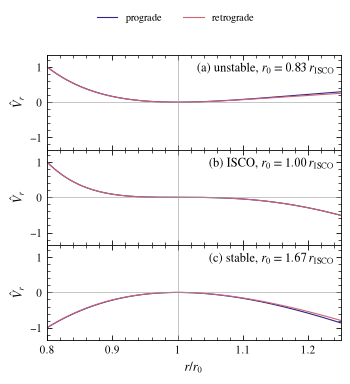

In [14]:
fig, axes = new_figure(PAPER_WIDTH, height=96, nrows=len(radii), sharex=True)

for ax, tag, (x, label) in zip(axes, "abc", radii.items()):
    for c, (sign, name) in zip(COLORS, branches.items()):
        ax.plot(x_span, potential[sign][x], color=c, label=name)
    ax.axhline(0, color="0.6", lw=0.4)
    ax.axvline(1, color="0.6", lw=0.4)
    ax.text(0.98, 0.92, rf"({tag}) {label}, $r_0={x:.2f}\,r_{{\rm ISCO}}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=TAG_SIZE)
    ax.set(ylabel=r"$\hat V_r$", ylim=(-1.35, 1.35))

axes[-1].set(xlabel=r"$r/r_0$", xlim=(x_span.min(), x_span.max()))
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=2,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'isco', 'circular-potential')
plt.show()

Measurement, for each branch and radius:

* start at $r_0(1+\delta)$, $\delta=10^{-4}$, with $u^r=0$ and $d\phi/dt=\Omega_{\rm circular}(r_0)$; PyGRO and KerrGeoPy get the same state
* PyGRO's own test lets numerical error seed the instability (its footnote 6), which depends on the tolerance; a fixed $\delta$ gives every code the same start
* follow 300 turns of $T_\phi=2\pi/\Omega_{\rm circular}(r_0)$ in coordinate time, long enough to see whether the error keeps growing
* Relatipy: `method="projection_radau"` (as in sections 1.2, 1.3 and 3) and `"dop853"`, `rtol=1e-12`, `max_step` $=T_\phi/100$; PyGRO: `rkf78`, `goal=12`, `hmax` $=T_\phi/100$
* KerrGeoPy (`kg.Orbit` from the initial position and four-velocity): closed-form $t(\lambda)$, $r(\lambda)$, $\phi(\lambda)$ in Mino time $\lambda$; evaluated at the coordinate times of each integrator by inverting $t(\lambda)$ (`kerrgeopy_at`), and used as the reference
* error: $|r-r_{\rm KerrGeoPy}(t)|/r_0$ at every stored sample
* trend: the largest error in each window of 20 turns, longer than the radial period of the unstable and ISCO orbits, so the oscillation of the error does not hide its growth

Why $\delta=10^{-4}$ and not smaller:

* KerrGeoPy finds the turning points as roots of the radial polynomial (`numpy` roots); a nearly circular orbit has a nearly double root, resolved only to $\sim10^{-8}$: with $\delta=10^{-8}$ it starts $\sim10^{-8}r_0$ off and classifies the retrograde stable orbit as plunging
* the unstable orbit starts at a turning point just outside the potential maximum. With $\delta=10^{-8}$ that forbidden gap is so thin that the integration error lets the orbit through: the retrograde one fell into the horizon in both integrators, while KerrGeoPy shows it bouncing back at $r_0(1+\delta)$ every cycle

In [ ]:
def kerrgeopy_orbit(bh, orbit):
    """KerrGeoPy orbit from the initial state of a relatipy orbit (Boyer-Lindquist, units of M)."""
    T0 = time_scale(bh)
    position = (
        0.0,
        (orbit.R / bh.r_g).to_value(u.one),
        orbit.Theta.to_value(u.rad),
        orbit.Phi.to_value(u.rad),
    )
    velocity = (
        float(orbit.ut.value),
        (orbit.uR / const.c).to_value(u.one),
        (orbit.uTheta * T0).to_value(u.rad),
        (orbit.uPhi * T0).to_value(u.rad),
    )
    return kg.Orbit(bh.spin, position, velocity)


def kerrgeopy_at(geodesic, t):
    """KerrGeoPy (r, phi) at coordinate times t [M]: its t(lambda) inverted by Newton steps."""
    t_of, r_of, _, phi_of = geodesic.trajectory()
    lam_max = 1.0
    while t_of(lam_max) < t.max():
        lam_max *= 2
    grid = np.linspace(0, lam_max, 20000)
    lam = np.interp(t, t_of(grid), grid)
    h = 1e-6 * lam_max
    for _ in range(4):
        lam -= (t_of(lam) - t) * 2*h / (t_of(lam + h) - t_of(lam - h))
    return r_of(lam), phi_of(lam)


N_TURNS = 300


def circular_stability(bh, x, sign, method="projection_radau", pygro=True, delta=1e-4, n_turns=N_TURNS, goal=12):
    """Circular orbit at x * r_ISCO nudged outward by delta: error of Relatipy (and PyGRO) against KerrGeoPy."""
    T0 = time_scale(bh)
    r0 = x * r_isco(bh.spin, sign)
    omega = circular_frequency(r0, bh.spin, sign)
    T_phi = 2*np.pi / abs(omega)
    orbit = bh.orbit(
        R=r0 * (1 + delta) * bh.r_g,
        Theta=90 * u.deg,
        Phi=0 * u.rad,
        vPhi=omega * u.rad / T0,
    )
    tau_end = n_turns * T_phi    # u^t >= 1, so coordinate time reaches n_turns * T_phi
    geodesic = kerrgeopy_orbit(bh, orbit)

    sol = orbit.solve(
        tau_span=(0 * T0, tau_end * T0),
        method=method,
        rtol=10.0**-goal,
        max_step=T_phi / 100 * T0,
    )
    t = (sol.t / T0).to_value(u.one)
    keep = t <= n_turns * T_phi
    r = (sol.R / bh.r_g).to_value(u.one)[keep]
    r_kg, _ = kerrgeopy_at(geodesic, t[keep])    # KerrGeoPy at the coordinate times of each integrator
    result = dict(turns=t[keep] / T_phi, error=np.abs(r - r_kg) / r0)

    if pygro:
        geo = pygro_solve(bh, orbit, tau_end, goal=goal, hmax=T_phi / 100)
        t_pygro, r_pygro = np.asarray(geo.x)[:, 0], np.asarray(geo.x)[:, 1]
        keep = t_pygro <= n_turns * T_phi
        r_kg, _ = kerrgeopy_at(geodesic, t_pygro[keep])
        result.update(turns_pygro=t_pygro[keep] / T_phi, error_pygro=np.abs(r_pygro[keep] - r_kg) / r0)
    return result


stability = {
    sign: {x: circular_stability(bh, x, sign) for x in radii}
    for sign in branches
}
stability_dop853 = {
    sign: {x: circular_stability(bh, x, sign, method="dop853", pygro=False) for x in radii}
    for sign in branches
}


In [ ]:
from matplotlib.ticker import LogFormatterSciNotation, LogLocator, NullFormatter

WINDOW = 20    # [T_phi]
INTEGRATORS = {
    "Relatipy, Radau with projection": dict(color=COLORS[0], marker="o", ls="-"),
    "Relatipy, DOP853": dict(color=COLORS[0], marker="^", ls="--"),
    "PyGRO, RKF78": dict(color=COLORS[1], marker="s", ls="-"),
}
FULL_WIDTH = rp.plotting.TARGETS["aanda"].full_width_mm    # A&A two-column width [mm]


def integrator_errors(sign, x):
    """(turns, error) of each integrator for one orbit."""
    s, d = stability[sign][x], stability_dop853[sign][x]
    return {
        "Relatipy, Radau with projection": (s["turns"], s["error"]),
        "Relatipy, DOP853": (d["turns"], d["error"]),
        "PyGRO, RKF78": (s["turns_pygro"], s["error_pygro"]),
    }


def window_max(turns, error, width=WINDOW):
    """Centre and largest error of each window of `width` turns."""
    edges = np.arange(0, N_TURNS + width, width)
    index = np.digitize(turns, edges) - 1
    return edges[:-1] + width / 2, np.array([error[index == i].max() for i in range(edges.size - 1)])


def plot_stability():
    """Rows: branch; columns: orbit; largest error in each window against KerrGeoPy."""
    fig, grid = new_figure(FULL_WIDTH, height=80, nrows=2, ncols=3, sharex=True)
    fig.get_layout_engine().set(w_pad=0.02, wspace=0.02, hspace=0)
    for row, (sign, name) in zip(grid, branches.items()):
        for ax, (x, label) in zip(row, radii.items()):
            for integrator, (turns, error) in integrator_errors(sign, x).items():
                ax.plot(*window_max(turns, error), lw=0.8, ms=2.5, mfc="none", label=integrator,
                        **INTEGRATORS[integrator])
            ax.set(xscale="log", yscale="log")
            ax.yaxis.set_major_locator(LogLocator(numticks=4))
            ax.yaxis.set_minor_formatter(NullFormatter())
            if sign == +1:
                ax.set_title(rf"{label}, $r_0={x:.2f}\,r_{{\rm ISCO}}$", fontsize=TAG_SIZE)
        row[0].set_ylabel(name, fontsize=TAG_SIZE)
    for ax in grid.flat:    # y range: smallest to largest value shown, with a small margin for the markers
        values = np.concatenate([line.get_ydata() for line in ax.lines])
        low, high = values.min(), values.max()
        margin = (high / low)**0.05
        ax.set_ylim(low / margin, high * margin)
        if high / low < 10:    # less than a decade: ticks at 1, 2 and 5
            ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
            ax.yaxis.set_major_formatter(LogFormatterSciNotation(labelOnlyBase=False))
    for ax in grid[-1]:
        ax.set(xlabel=r"$t/T_\phi$")
    fig.supylabel(r"$|r-r_{\rm KerrGeoPy}|/r_0$", fontsize=STYLE.target.label_size)
    fig.legend(*grid[0, 0].get_legend_handles_labels(), loc="outside upper center", ncols=3, frameon=False)
    glue_panels(fig)
    save_paper_figure(fig, 'isco', 'circular-stability')
    return fig


In [ ]:
fig = plot_stability()
plt.show()


Reading the figure (rows: branch; columns: orbit; one point per window of 20 turns):

* unstable orbit: the error grows each time the orbit passes near $r_0$, where a small difference is amplified; PyGRO grows fastest, Relatipy with Radau and projection slowest
* ISCO: the two explicit methods, DOP853 and RKF78, grow steadily; Radau with projection does not
* stable orbit: the three stay at $10^{-12}$ to $10^{-11}$, the accuracy of the reference itself (the Relatipy error does not change between `rtol=1e-10` and `1e-13`), so there is no trend to compare

Largest error $|r-r_{\rm KerrGeoPy}(t)|/r_0$ in the first and last windows (quoted in the paper):


In [ ]:
Table(rows=[
    dict(branch=name, orbit=label, integrator=integrator,
         first=window_max(turns, error)[1][0], last=window_max(turns, error)[1][-1])
    for sign, name in branches.items()
    for x, label in radii.items()
    for integrator, (turns, error) in integrator_errors(sign, x).items()
])


## 2. Lense–Thirring: nodal precession

A spinning black hole drags the plane of an inclined orbit: its ascending node $\Omega$ turns about the spin. The measured advance of the node is compared with the lowest post-Newtonian change per orbit of [Merritt et al. 2010](https://arxiv.org/abs/0911.4718), Sect. II.B, which adds the frame-dragging and the spin-quadrupole terms.

Change of the node per orbit (eq. 8):

$$\delta\Omega=A_J-A_Q\cos i$$

Frame dragging and quadrupole amplitudes (eqs. 6b and 6c):

$$A_J=\frac{4\pi\chi}{c^3}\left[\frac{GM}{(1-e^2)a}\right]^{3/2},\qquad A_Q=\frac{3\pi\chi^2}{c^4}\left[\frac{GM}{(1-e^2)a}\right]^{2}$$

* $i$: "the angle between the SBH spin vector and the stellar orbital angular momentum vector", so the node is measured about the spin
* $A_J$ does not depend on $i$; $A_Q$ goes with $\chi^2$, from the quadrupole $Q=-J^2/(cM)$ (eq. 4)
* "Both precessions leave the inclination with respect to the black hole spin unchanged"
* with $p=a(1-e^2)$, $\delta\Omega$ depends on the orbit only through $p$ and $i$
* reference values of the frame-dragging term from [Piran et al. 2026](https://arxiv.org/abs/2607.24931) (their Table 1 footnote, $\chi=1$): $9.6\times10^{-4}$ (S301) and $3.3\times10^{-5}$ rad/orbit (S2)

Black hole and stars of Piran et al.: $M_{\rm BH}=4.3\times10^6\,M_\odot$ (Sect. 3), distance $8.28$ kpc (Table 3 footnote), semi-major axis and eccentricity of S301 and S2 (Table 3).


How positions are read from Relatipy:

* `KerrMcmcModel.get_ra_dec_vr` returns sky offsets. With `t_eval` (coordinate time, no Rømer delay), the Dec and RA offsets are the $x$ and $y$ coordinates of the observer frame times $M/D$ (`rp_kerr_observables_project` in `native/src/geodesic/physic/kerr_observables.c`)
* `spin_frame_positions`: a second observer whose axes are a cyclic permutation of the first one (`CYCLE`) sees $z$ as its Dec offset. Initial state and spin direction are rotated together, and the $x$ seen by both observers must agree
* `initial_state`: Cartesian state from Keplerian elements measured from the equatorial plane (`Kerr.orbit` at $\chi=0$), starting at apocentre

Elements are measured at every apocentre, where the orbit plane is quiet (`apocentre_elements`):

* orbit pole: $\mathbf r(t_1)\times\mathbf r(t_2)$ at $t_{1,2}=t_{\rm apo}\mp0.05\,T$, two points of the same plane
* node $\Omega$ about the spin $\hat z$, inclination $i$, and argument of pericentre $\omega$ from the apocentre direction, located with a quadratic fit of $r(t)$ over $1001$ samples
* the advance per orbit is the difference between consecutive apocentres

In [11]:
PIRAN_MASS = 4.3e6 * u.Msun        # Piran et al., Sect. 3
PIRAN_DISTANCE = 8.28 * u.kpc      # Piran et al., Table 3 footnote
sgr = rp.Kerr(mass=PIRAN_MASS, spin=0.0)
LENGTH = sgr.r_g.to(u.au)    # M [au]
TIME = time_scale(sgr)       # M [s]
SKY = (sgr.r_g / PIRAN_DISTANCE).to_value(u.arcsec, u.dimensionless_angles())    # arcsec per M at PIRAN_DISTANCE
CYCLE = np.array([[0., 0., 1.], [1., 0., 0.], [0., 1., 0.]])    # second observer: its Dec offset is z
SOLVER = dict(method="dop853", rtol=1e-12, atol=1e-14, max_steps=10**8)

STARS = dict(    # Piran et al., Table 3: semi-major axis [M], eccentricity
    S301=dict(a=16010, e=0.9825),
    S2=dict(a=24100, e=0.8844),
)


def initial_state(a, e, inc, omega, f=np.pi):
    """Cartesian (x [au], v [au/s]) in the spin frame from Keplerian elements; apocentre by default."""
    orbit = sgr.orbit(a=a * LENGTH, e=e, inc=inc * u.rad, Omega=0 * u.rad, omega=omega * u.rad, f=f * u.rad)
    return (
        np.array([q.to_value(u.au) for q in (orbit.x, orbit.y, orbit.z)]),
        np.array([q.to_value(u.au / u.s) for q in (orbit.vx, orbit.vy, orbit.vz)]),
    )


def spin_frame_positions(state, t, chi=0.0, spin=(0, 0, 1)):
    """(x, y, z) [M] in the spin frame at coordinate times t [M], from the sky offsets seen by two observers."""
    position, velocity = state
    sky = []
    for rotation in (np.eye(3), CYCLE):
        x, v = rotation @ position, rotation @ velocity
        kerr = dict(mass=PIRAN_MASS, spin=chi, vec=tuple(rotation @ spin))
        orbit = dict(
            x=x[0] * u.au, y=x[1] * u.au, z=x[2] * u.au,
            vx=v[0] * u.au / u.s, vy=v[1] * u.au / u.s, vz=v[2] * u.au / u.s,
        )
        sol = dict(t_eval=t * TIME, **SOLVER)
        alpha, delta, _ = rp.KerrMcmcModel().get_ra_dec_vr(
            kerr=kerr, orbit=orbit, sol=sol, distance=PIRAN_DISTANCE)
        sky.append((delta / SKY, alpha / SKY))
    (x, y), (z, x_again) = sky
    mismatch = np.abs(x_again - x).max() / np.abs(x).max()
    assert mismatch < 1e-4, f"the two observers disagree: {mismatch:.1e}"
    return np.stack([x, y, z], axis=1)


def apocentre_elements(state, a, n_orbits, **kwargs):
    """Pole, inclination, node and argument of pericentre [rad] at every apocentre after the start, spin frame."""
    period = 2*np.pi * a**1.5
    t = np.linspace(0, n_orbits + 0.5, 100 * n_orbits + 51) * period
    r = np.linalg.norm(spin_frame_positions(state, t, **kwargs), axis=1)
    peaks = np.where((r[1:-1] > r[:-2]) & (r[1:-1] >= r[2:]))[0] + 1
    window = np.linspace(-0.05, 0.05, 1001) * period
    x = spin_frame_positions(state, np.concatenate([t[i] + window for i in peaks]), **kwargs).reshape(peaks.size, -1, 3)

    pole = np.cross(x[:, 0], x[:, -1])
    pole /= np.linalg.norm(pole, axis=1)[:, None]
    node = np.stack([-pole[:, 1], pole[:, 0], 0 * pole[:, 0]], axis=1)
    node /= np.linalg.norm(node, axis=1)[:, None]
    pericentre = []
    for x_k in x:
        j = np.clip(np.argmax(np.linalg.norm(x_k, axis=1)), 5, x_k.shape[0] - 6)
        s = slice(j - 5, j + 6)
        c = np.polyfit(window[s], np.linalg.norm(x_k[s], axis=1), 2)
        apocentre = [np.polyval(np.polyfit(window[s], x_k[s, i], 3), -c[1] / (2 * c[0])) for i in range(3)]
        pericentre.append(-np.array(apocentre) / np.linalg.norm(apocentre))
    pericentre = np.array(pericentre)
    return dict(
        inc=np.arccos(pole[:, 2]),
        Omega=np.unwrap(np.arctan2(pole[:, 0], -pole[:, 1])),
        omega=np.unwrap(np.arctan2(
            np.sum(pericentre * np.cross(pole, node), axis=1), np.sum(pericentre * node, axis=1))),
    )


def per_orbit(elements):
    """Node advance per orbit [rad] between consecutive apocentres, with the mean inclination and argument of pericentre."""
    return dict(
        dOmega=np.diff(elements["Omega"]),
        inc=(elements["inc"][1:] + elements["inc"][:-1]) / 2,
        omega=(elements["omega"][1:] + elements["omega"][:-1]) / 2,
    )

Measurement: $\chi=1$, spin along $\hat z$, $\omega=45^\circ$; mean over $2$ orbits; eccentricities of S301 and S2, $300\le p\le3\times10^4\,M$; two inclinations:

* $i=88^\circ$: nearly polar, the quadrupole term is small ($\cos i\approx0.035$) and the orbit stays off the coordinate poles
* $i=45^\circ$: the quadrupole term is a few per cent of $A_J$ at $p=300\,M$

Relative difference:

$$\varepsilon=\left|\frac{\Delta\Omega_{\rm Relatipy}}{\delta\Omega}-1\right|$$


In [12]:
def frame_dragging(a, e, chi):
    """A_J [rad per orbit], Merritt et al. eq. 6b in units G = c = M = 1."""
    return 4*np.pi * chi * (1 / ((1 - e**2) * a))**1.5


def quadrupole(a, e, chi):
    """A_Q [rad per orbit], Merritt et al. eq. 6c in units G = c = M = 1."""
    return 3*np.pi * chi**2 * (1 / ((1 - e**2) * a))**2


def node_per_orbit(a, e, chi, inc):
    """delta Omega per orbit [rad], node about the spin: Merritt et al. eq. 8."""
    return frame_dragging(a, e, chi) - quadrupole(a, e, chi) * np.cos(inc)


CHI_LT = 1.0
INCLINATIONS_LT = np.radians([88, 45])
p_lt = np.geomspace(300, 3e4, 10)
lense_thirring = Table(rows=[
    dict(
        star=star,
        e=orbit["e"],
        inc=np.degrees(inc),
        p=p,
        relatipy=np.mean(per_orbit(apocentre_elements(
            initial_state(p / (1 - orbit["e"]**2), orbit["e"], inc, np.pi/4),
            p / (1 - orbit["e"]**2), 3, chi=CHI_LT))["dOmega"]),
        merritt=node_per_orbit(p / (1 - orbit["e"]**2), orbit["e"], CHI_LT, inc),
        frame_dragging=frame_dragging(p / (1 - orbit["e"]**2), orbit["e"], CHI_LT),
    )
    for inc in INCLINATIONS_LT
    for star, orbit in STARS.items()
    for p in p_lt
])
lense_thirring["rel_error"] = np.abs(lense_thirring["relatipy"] / lense_thirring["merritt"] - 1)
lense_thirring["rel_error_frame_dragging"] = np.abs(lense_thirring["relatipy"] / lense_thirring["frame_dragging"] - 1)

Table(rows=[
    dict(
        star=star,
        piran_table_1=LT,
        A_J=frame_dragging(STARS[star]["a"], STARS[star]["e"], 1.0),
        relatipy=np.mean(per_orbit(apocentre_elements(
            initial_state(STARS[star]["a"], STARS[star]["e"], INCLINATIONS_LT[0], np.pi/4), STARS[star]["a"], 3, chi=1.0))["dOmega"]),
    )
    for star, LT in (("S301", 9.6e-4), ("S2", 3.3e-5))
])


star,piran_table_1,A_J,relatipy
str4,float64,float64,float64
S301,0.00096,0.0009599442225237191,0.0009770702703660564
S2,3.3e-05,3.3036034097039476e-05,3.308378389159893e-05


Figure: (a) node advance per orbit, eq. 8 (lines: $i=88^\circ$ solid, $i=45^\circ$ dashed) and Relatipy (markers: shape for the eccentricity of S301 or S2, open for $i=88^\circ$, filled for $i=45^\circ$); (b) $\varepsilon$ of Relatipy against eq. 8.


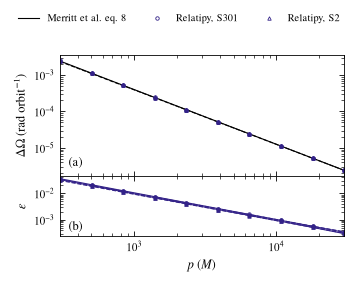

In [13]:
ECCENTRICITY_MARKERS = dict(S301="o", S2="^")
INCLINATION_STYLE = {88.0: dict(ls="-", mfc="none"), 45.0: dict(ls="--", mfc=COLORS[0])}

fig, (ax_w, ax_e) = new_figure(PAPER_WIDTH, height=70, nrows=2, sharex=True, height_ratios=(2, 1))
p_fine = np.geomspace(p_lt.min(), p_lt.max(), 200)
for inc in INCLINATIONS_LT:
    style = INCLINATION_STYLE[round(np.degrees(inc))]
    ax_w.plot(p_fine, node_per_orbit(p_fine, 0.0, CHI_LT, inc), color="k", ls=style["ls"], lw=0.8,
              label="Merritt et al. eq. 8" if inc == INCLINATIONS_LT[0] else None)
for (star, marker), inc in ((sm, inc) for inc in INCLINATIONS_LT for sm in ECCENTRICITY_MARKERS.items()):
    style = INCLINATION_STYLE[round(np.degrees(inc))]
    rows = lense_thirring[(lense_thirring["star"] == star) & np.isclose(lense_thirring["inc"], np.degrees(inc))]
    label = f"Relatipy, {star}" if inc == INCLINATIONS_LT[0] else None
    ax_w.plot(rows["p"], rows["relatipy"], marker, color=COLORS[0], ms=2.5, mfc=style["mfc"], mew=0.6, label=label)
    ax_e.plot(rows["p"], rows["rel_error"], marker, color=COLORS[0], ms=2.5, mfc=style["mfc"], mew=0.6,
              ls=style["ls"], lw=0.8)

ax_w.set(ylabel=r"$\Delta\Omega$ (rad orbit$^{-1}$)", yscale="log")
ax_e.set(xlabel=r"$p$ ($M$)", ylabel=r"$\varepsilon$", xscale="log", yscale="log",
         xlim=(p_lt.min(), p_lt.max()))
for ax, tag in ((ax_w, "(a)"), (ax_e, "(b)")):
    ax.text(0.03, 0.06, tag, transform=ax.transAxes, va="bottom", fontsize=TAG_SIZE)
fig.legend(*ax_w.get_legend_handles_labels(), loc="outside upper center", ncols=3,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'lense-thirring', 'lense-thirring-node')
plt.show()


$\varepsilon$ at the smallest and largest $p$ of the sweep (quoted in the paper), against eq. 8 and against $A_J$ alone:


In [14]:
Table(rows=[
    dict(
        star=star,
        inc=inc,
        rel_error_p_min=rows["rel_error"][0],
        rel_error_p_max=rows["rel_error"][-1],
        rel_error_frame_dragging_p_min=rows["rel_error_frame_dragging"][0],
        rel_error_frame_dragging_p_max=rows["rel_error_frame_dragging"][-1],
    )
    for inc in np.degrees(INCLINATIONS_LT)
    for star in STARS
    for rows in [lense_thirring[(lense_thirring["star"] == star) & np.isclose(lense_thirring["inc"], inc)]]
])


star,inc,rel_error_p_min,rel_error_p_max,rel_error_frame_dragging_p_min,rel_error_frame_dragging_p_max
str4,float64,float64,float64,float64,float64
S301,88.0,0.035748121232816565,0.00034119932775644735,0.03418290640264399,0.00019002851235039309
S2,88.0,0.032943585970119704,0.00030329840818899,0.03138260933270365,0.00015213332034158533
S301,45.0,0.03328463247326252,0.00035851977650502853,0.0016468811155283536,0.0027044401401177254
S2,45.0,0.030674184766849688,0.0003136458187098512,0.0008836382798730336,0.0027491767000388245


Reading:

* (a): both eccentricities and both inclinations fall on eq. 8, $\propto p^{-3/2}$
* (b): against eq. 8 the difference falls as $1/p$, from $3\%$ at $p=300\,M$ to $3\times10^{-4}$ at $3\times10^4\,M$, and is the same at $i=88^\circ$ and $i=45^\circ$: the next post-Newtonian order, which eq. 8 leaves out
* against $A_J$ alone (table above), the difference at $i=45^\circ$ does not fall as $1/p$: it stays near $3\times10^{-3}$ at $3\times10^4\,M$, the quadrupole term $A_Q\cos i$, which falls only as $p^{-1/2}$ relative to $A_J$
* at the elements of S301 and S2 (first table), $A_J$ gives the values quoted by Piran et al.


## 3. Pericentre precession

All formulas of this section are from [Bini, Geralico & Jantzen 2016](https://doi.org/10.1103/PhysRevD.94.064066), for bound equatorial Kerr geodesics in Boyer–Lindquist coordinates.

Orbit parametrised by the phase $\zeta$ (eqs. 8 and 9):

$$r=\frac{Mp}{1+e\cos\zeta}$$

$$r_{\rm per}=\frac{Mp}{1+e},\qquad r_{\rm apo}=\frac{Mp}{1-e}$$

* $p$: dimensionless semi-latus rectum, $u_p=1/p$; $e$: eccentricity
* $\zeta$: orbital phase, $\zeta=0$ at the pericentre, $\zeta=\pi$ at the apocentre, one radial period for $\zeta\in[0,2\pi]$. The paper calls it $\chi$; renamed here because $\chi$ is the spin in this notebook (`phase` in the code)
* $x=L-\chi ME$, $\hat x=x/M$ (text before eq. 5); $E$, $L$: energy and angular momentum per unit mass

Azimuth per unit phase (eq. 25):

$$\frac{d\phi}{d\zeta}=u_p^{1/2}\,\frac{\mathcal{N}(\zeta)}{\mathcal{D}_1(\zeta)\,\mathcal{D}_2(\zeta)}$$

$$\mathcal{N}(\zeta)=\hat x+\chi E-2u_p\hat x(1+e\cos\zeta)$$

$$\mathcal{D}_1(\zeta)=\left[1+u_p^2\hat x^2(e^2-2e\cos\zeta-3)\right]^{1/2}$$

$$\mathcal{D}_2(\zeta)=1-2u_p(1+e\cos\zeta)+\chi^2u_p^2(1+e\cos\zeta)^2$$

* $\mathcal{N}$, $\mathcal{D}_1$, $\mathcal{D}_2$: only names for the numerator and the two factors of the denominator of eq. 25, so that it fits on the page

Pericentre advance per radial period, "for any eccentricity" (eq. 27):

$$\Delta\phi_{\rm orb}=\int_0^{2\pi}\frac{d\phi}{d\zeta}\,d\zeta-2\pi\,{\rm sgn}\!\left(\frac{d\phi}{d\zeta}\right)$$

* exact: no expansion in $u_p$, $e$ or $\chi$
* `exact_precession` evaluates eq. 27 with eq. 25 by the midpoint rule in $\zeta$; the integrand is smooth and periodic, so `n=4096` reaches machine precision
* $E$ and $L$ are those of the integrated orbit (`orbit.get_E()`, `orbit.get_Lz()`); prograde orbits, ${\rm sgn}=+1$

In [24]:
def exact_precession(chi, E, Lz, p, e, n=4096):
    """Pericentre advance [rad] per radial period of a prograde equatorial orbit: Bini et al. 2016, eqs. 25 and 27 (M = 1)."""
    u_p = 1 / p
    x = Lz - chi * E
    cos_phase = np.cos((np.arange(n) + 0.5) * 2*np.pi / n)    # orbital phase zeta (chi in Bini et al.), not the spin
    dphi_dchi = u_p**0.5 * (x + chi*E - 2*u_p*x*(1 + e*cos_phase)) / (
        np.sqrt(1 + u_p**2 * x**2 * (e**2 - 2*e*cos_phase - 3))
        * (1 - 2*u_p*(1 + e*cos_phase) + chi**2 * u_p**2 * (1 + e*cos_phase)**2)
    )
    return 2*np.pi * np.mean(dphi_dchi) - 2*np.pi

The integrated advance is read from the pericentres, the same way for every code (`hermite_pericentres`):

* bracket each pericentre between the two stored samples where $u^r$ changes sign from negative to positive
* on that step, build the cubic Hermite interpolant of $r(\tau)$ from $r$ and $dr/d\tau=u^r$ at both ends; the pericentre is its minimum
* $\Phi$ there from the cubic Hermite interpolant of $\Phi(\tau)$ with $d\Phi/d\tau=u^\phi$
* only stored states and velocities are used, the same recipe for every code; its error grows with the step between stored samples (see the reading of section 3.1)

Mean advance over the $N$ cycles stored:

$$\Delta\phi_{\rm int}=\frac{\Phi_N-\Phi_0}{N}-2\pi$$

In [25]:
def mean_advance(phases):
    """Mean advance per cycle [rad] from consecutive pericentre phases."""
    return (phases[-1] - phases[0]) / (phases.size - 1) - 2*np.pi


def measure_precession(bh, a, e, rtol=None, goal=10, n_periods=100):
    """Pericentre advance of an equatorial prograde orbit: exact, relatipy, PyGRO and post-Newtonian."""
    p = a * (1 - e**2)
    p_M = (p / bh.r_g).to_value(u.one)
    orbit = bh.orbit(p=p, e=e, x=1.0)
    T0 = time_scale(bh)
    tau_end = n_periods * (orbit.get_keplerian_period() / T0).to_value(u.one)
    exact = exact_precession(bh.spin, orbit.get_E(), orbit.get_Lz(), p_M, e)

    sol = orbit.solve(
        tau_span=(0 * T0, tau_end * T0),
        method="projection_radau",
        rtol=rtol,
    )
    measured = mean_advance(hermite_pericentres(
        (sol.tau / T0).to_value(u.one),
        (sol.R / bh.r_g).to_value(u.one),
        (sol.uR / const.c).to_value(u.one),
        sol.Phi.to_value(u.rad),
        (sol.uPhi * T0).to_value(u.rad),
    ))

    geo = pygro_solve(bh, orbit, tau_end, goal)
    measured_pygro = mean_advance(hermite_pericentres(
        geo.tau, geo.x[:, 1], geo.u[:, 1], geo.x[:, 3], geo.u[:, 3]))

    return dict(
        exact=exact,
        measured=measured,
        post_newtonian=6*np.pi / p_M - 8*np.pi * bh.spin / p_M**1.5 + 3*np.pi * bh.spin**2 / p_M**2,
        rel_error=abs(measured / exact - 1),
        rel_error_pygro=abs(measured_pygro / exact - 1),
    )

### 3.1. Pericentre advance vs. semi-major axis and eccentricity

Fixed spin $\chi=0.9$, equatorial prograde orbits (`x=1`). On the equator every radial cycle has the same advance, so the mean over a few cycles can be compared with eq. 27 directly; an inclined orbit adds a polar modulation of $\Phi$ at each pericentre that only averages out as $1/N$.

Each orbit is given by $p$ and $e$ of eqs. 8–9 (the `p=` and `e=` arguments of `bh.orbit`). The sweep variable is the semi-major axis $a$, *defined* here by

$$a\equiv\frac{p}{1-e^2}$$

so that $a=(r_{\rm per}+r_{\rm apo})/2$ with eq. 9.

Integration:

* `method="projection_radau"`: Radau steps, each accepted step projected back onto the initial norm $u^\mu u_\mu=-1$, $E$, $L_z$ and $Q$
* `100` Keplerian periods of $a$; they hold $N\approx55$–$98$ radial periods (fewer at small $a$, where the radial period is longer than the Keplerian one)
* two tolerances: the library default `rtol=1e-10` and `rtol=1e-12`

Relative error against the exact value:

$$\varepsilon=\left|\frac{\Delta\phi_{\rm int}}{\Delta\phi_{\rm orb}}-1\right|$$

$\varepsilon$ is an absolute error of $\Phi$ divided by $\Delta\phi_{\rm orb}$, and holds two parts:

* integration error of $\Phi$ over the $N$ cycles, set by `rtol`
* error of the cubic Hermite location of the first and last pericentre (cell above), divided by $N$; set by the spacing of the stored samples, not by `rtol`

$\Delta\phi_{\rm orb}$ falls as $1/p$ (leading term below), so a fixed absolute error appears as $\varepsilon$ growing with $p$.

The first-order post-Newtonian advance per orbit is shown as reference ([Will 2008](https://doi.org/10.1086/528847), eq. 2a, with the amplitudes of eqs. 3a–3c):

$$\Delta\varpi=A_S-2A_J\cos\alpha-\frac12A_Q\left(1-3\cos^2\alpha\right)$$

$$A_S=\frac{6\pi M}{p},\qquad A_J=4\pi\chi\left(\frac{M}{p}\right)^{3/2},\qquad A_Q=3\pi\chi^2\left(\frac{M}{p}\right)^2$$

* $\alpha$: angle between the spin and the orbit normal; $\alpha=0$ for the equatorial prograde orbits here
* $\chi=J/M^2$: dimensionless spin

With these values:

$$\Delta\phi_{\rm PN}=\frac{6\pi M}{p}-8\pi\chi\left(\frac{M}{p}\right)^{3/2}+3\pi\chi^2\left(\frac{M}{p}\right)^2$$

Will's $p$ is the post-Newtonian semi-latus rectum; here the Boyer–Lindquist $p$ is used. The two agree at leading order, so the curve is a weak-field reference, not a prediction at order $(M/p)^2$.

In [26]:
bh = rp.Kerr(mass=4.3e6*u.Msun, spin=0.9)
tolerances = ((None, 10), (1e-12, 12))    # (relatipy rtol, PyGRO goal); None = default rtol=1e-10

a_grid = np.geomspace(20, 1e4, 20)
e_values = (0.2, 0.5, 0.8)
sweep_a = {
    (e, rtol): Table(rows=[measure_precession(bh, a*bh.r_g, e, rtol, goal) for a in a_grid])
    for e in e_values for rtol, goal in tolerances
}

Same measurement at fixed $a$, sweeping $e$. At fixed $a$, $p=a(1-e^2)$ shrinks as $e$ grows, so the pericentre moves inwards and the advance grows. The sweep stays above the separatrix: $p\geq5.7\,M$ at $a=30\,M$, $e=0.9$.

In [27]:
e_grid = np.linspace(0.05, 0.9, 20)
a_values = (30, 100, 1000)
sweep_e = {
    (a, rtol): Table(rows=[measure_precession(bh, a*bh.r_g, e, rtol, goal) for e in e_grid])
    for a in a_values for rtol, goal in tolerances
}

Figure for the paper, both sweeps at $\chi=0.9$:

* (a) against the semi-major axis $a$, for $e=0.2,\ 0.5,\ 0.8$
* (b) against the eccentricity $e$, for $a=30,\ 100,\ 1000\,M$
* top: exact advance, eq. 27 (solid), post-Newtonian (dotted) and Relatipy integration (circles, `rtol=1e-10`)
* below: $\varepsilon$ of the Relatipy value, one panel per `rtol`
* PyGRO is integrated in the same call (`measure_precession`) but only enters section 3.2

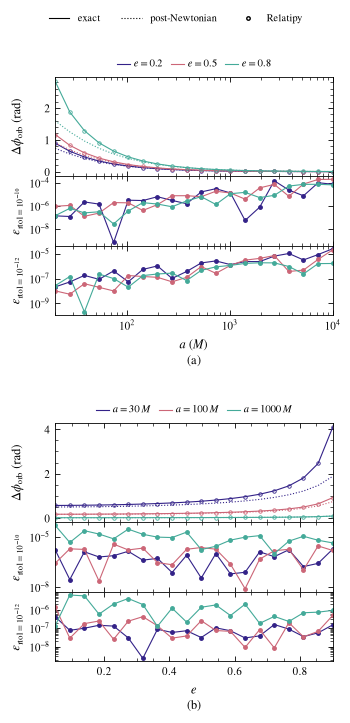

In [28]:
def plot_precession(blocks_data):
    """Pericentre advance (top) and Relatipy integration error per rtol; one block per sweep, stacked."""
    fig, blocks = stacked_blocks(height=182, ratios=(2, 1.4, 1.4))

    for (ax_phi, *ax_err), block in zip(blocks, blocks_data):
        for c, curve in zip(COLORS, block["curves"]):
            default = block["sweep"][curve, None]
            ax_phi.plot(block["x"], default["exact"], color=c, label=block["label"](curve))
            ax_phi.plot(block["x"], default["post_newtonian"], color=c, ls=":")
            ax_phi.plot(block["x"], default["measured"], "o", color=c, ms=2.5, mfc="none", mew=0.6)
            for ax, (rtol, goal) in zip(ax_err, tolerances):
                ax.plot(block["x"], block["sweep"][curve, rtol]["rel_error"], "o-", color=c, ms=2.5, lw=0.8)

        ax_phi.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncols=3, frameon=False,
                      borderaxespad=0.3, handlelength=1.2, handletextpad=0.4, columnspacing=0.8)
        ax_phi.set(xscale=block["xscale"], ylabel=r"$\Delta\phi_{\rm orb}$ (rad)")
        for ax, exponent in zip(ax_err, (10, 12)):
            ax.set(ylabel=rf"$\varepsilon_{{\mathrm{{rtol}}=10^{{-{exponent}}}}}$", yscale="log")
        ax_err[-1].set(xlabel=block["xlabel"] + "\n" + block["tag"], xlim=(block["x"].min(), block["x"].max()))

    # Style-only handles for the shared legend
    handles = [
        plt.Line2D([], [], color="k", label="exact"),
        plt.Line2D([], [], color="k", ls=":", label="post-Newtonian"),
        plt.Line2D([], [], color="k", marker="o", ls="none", ms=2.5, mfc="none", label="Relatipy"),
    ]
    fig.legend(handles=handles, loc="outside upper center", ncols=3, frameon=False, borderpad=0.8)
    glue_panels(fig, blocks)
    return fig


fig = plot_precession([
    dict(tag="(a)", x=a_grid, sweep=sweep_a, curves=e_values,
         label=lambda e: rf"$e={e}$", xlabel=r"$a$ ($M$)", xscale="log"),
    dict(tag="(b)", x=e_grid, sweep=sweep_e, curves=a_values,
         label=lambda a: rf"$a={a}\,M$", xlabel=r"$e$", xscale="linear"),
])
save_paper_figure(fig, "precession", "precession")
plt.show()

Reading:

* top: the circles fall on eq. 27 over the whole sweep. The post-Newtonian curve departs at small $p$: at $a=20\,M$, $e=0.8$ ($p=7.2\,M$) eq. 27 gives $2.83$ rad and $\Delta\phi_{\rm PN}$ gives $1.59$ rad; at $a=30\,M$, $e=0.9$ ($p=5.7\,M$), $4.09$ against $1.88$ rad
* small $a$ ($\lesssim50\,M$): $\varepsilon$ is the integration error, and drops by $\sim10^2$ from `rtol=1e-10` to `1e-12`
* large $a$: $\varepsilon$ grows roughly as $a$ in both panels. The absolute error of the advance does not grow; $\Delta\phi_{\rm orb}$ shrinks as $1/p$
* that floor comes from the pericentre location, not from the integrator. Check at $a=1000\,M$, $e=0.5$, `rtol=1e-12` (run outside this notebook with the cells above, 2026-10-29):

| step | samples per radial period | scatter of single-cycle advance (rad) | error of mean advance (rad) |
|---|---|---|---|
| default | $\approx130$ | $1.8\times10^{-6}$ | $6.4\times10^{-8}$ |
| `max_step` $=P/1000$ | $\approx1000$ | $1.9\times10^{-7}$ | $2.4\times10^{-9}$ |
| `max_step` $=P/4000$ | $\approx4000$ | $1.9\times10^{-9}$ | $3.1\times10^{-11}$ |

* $P$: Keplerian period; with `max_step` $=P/1000$, `rtol=1e-10` gives the same digits as `1e-12`; the error falls roughly as the fourth power of the step, as expected from the cubic Hermite interpolant
* at large $a$, `rtol=1e-12` sits below `1e-10` only because it stores about twice as many samples per radial period ($\approx130$ against $\approx60$)
* (b): $\varepsilon$ barely depends on $e$ and is ordered by $a$ ($a=1000\,M$ highest), the same floor divided by $\Delta\phi_{\rm orb}$
* so the integrated advance agrees with eq. 27 to $\lesssim5\times10^{-7}$ rad per radial period at `rtol=1e-10` and $\lesssim6\times10^{-8}$ rad at `1e-12` (check at $e=0.5$, $a=20$–$10^4\,M$); above $a\sim100\,M$, $\varepsilon$ is an upper bound set by the pericentre sampling

### 3.2. Comparison with KerrGeoPy and PyGRO

**Exact value.** Three evaluations of $\Delta\phi_{\rm orb}$ for the same orbits of section 3.1:

* `exact_precession`: eqs. 25 and 27 of Bini et al., midpoint rule in double precision
* KerrGeoPy: its Boyer–Lindquist-time frequencies $\Omega_r$, $\Omega_\phi$ (`fundamental_frequencies`, closed form with elliptic integrals), inserted in eq. 27 through the definitions of Bini et al. (eqs. 28 and 29):

$$T_r=\int_0^{2\pi}\frac{dt}{d\zeta}\,d\zeta,\qquad \Omega_r=\frac{2\pi}{T_r}$$

$$\Omega_\phi=\frac{1}{T_r}\int_0^{2\pi}\frac{d\phi}{d\zeta}\,d\zeta$$

  With eq. 29, the integral in eq. 27 is $T_r\Omega_\phi$; with eq. 28, $T_r=2\pi/\Omega_r$. Substituted in eq. 27:

$$\Delta\phi_{\rm orb}=2\pi\frac{\Omega_\phi}{\Omega_r}-2\pi$$

* reference: eqs. 25 and 27 again, integrated with `mpmath` at 40 digits, fed with each code's own $E$ and $L$, so only the evaluation of the integral is compared

**Integrated orbits.** Relative error $\varepsilon$ of section 3.1 for Relatipy and PyGRO, same initial state and proper time, Relatipy `rtol=1e-12` with PyGRO `goal=12`, over a Monte Carlo sample of orbits.

In [29]:
mp.mp.dps = 40


def mpmath_precession(chi, E, Lz, p, e):
    """Bini et al. 2016, eqs. 25 and 27, integrated at 40 digits (prograde, M = 1); phase = zeta (chi in Bini et al.)."""
    chi, E, Lz, p, e = (mp.mpf(v) for v in (chi, E, Lz, p, e))
    u_p = 1 / p
    x = Lz - chi * E

    def dphi_dchi(phase):
        s = 1 + e * mp.cos(phase)
        return u_p**mp.mpf(0.5) * (x + chi*E - 2*u_p*x*s) / (
            mp.sqrt(1 + u_p**2 * x**2 * (e**2 - 2*e*mp.cos(phase) - 3))
            * (1 - 2*u_p*s + chi**2 * u_p**2 * s**2)
        )

    return float(mp.quad(dphi_dchi, [0, mp.pi, 2*mp.pi]) - 2*mp.pi)


def exact_comparison(bh, a, e):
    """Relative difference of exact_precession and KerrGeoPy against the 40-digit reference."""
    p_M = (a * (1 - e**2) / bh.r_g).to_value(u.one)
    orbit = bh.orbit(p=a * (1 - e**2), e=e, x=1.0)
    E, Lz = orbit.get_E(), orbit.get_Lz()
    ours = exact_precession(bh.spin, E, Lz, p_M, e)

    kerr = kg.StableOrbit(bh.spin, p_M, e, 1.0)
    omega_r, omega_theta, omega_phi = kerr.fundamental_frequencies()
    kerrgeopy = 2*np.pi * omega_phi / omega_r - 2*np.pi

    return dict(
        ours=abs(ours / mpmath_precession(bh.spin, E, Lz, p_M, e) - 1),
        kerrgeopy=abs(kerrgeopy / mpmath_precession(bh.spin, kerr.E, kerr.L, p_M, e) - 1),
    )


exact_a = {e: Table(rows=[exact_comparison(bh, a*bh.r_g, e) for a in a_grid]) for e in e_values}
exact_e = {a: Table(rows=[exact_comparison(bh, a*bh.r_g, e) for e in e_grid]) for a in a_values}

Check of the exact value (notebook only, not in the paper): relative difference $\varepsilon_{\rm ref}$ of each evaluation of eq. 27 from the 40-digit reference, same sweeps as section 3.1.

* Bini et al. eq. 27: `exact_precession`, the value used as exact in section 3.1
* KerrGeoPy: its closed form, $2\pi\Omega_\phi/\Omega_r-2\pi$
* values below $\epsilon_{\rm mach}$ are drawn at $\epsilon_{\rm mach}$
* both stay far below $\varepsilon$ of section 3.1, so $\varepsilon$ there comes from the integration and the pericentre location, not from the reference

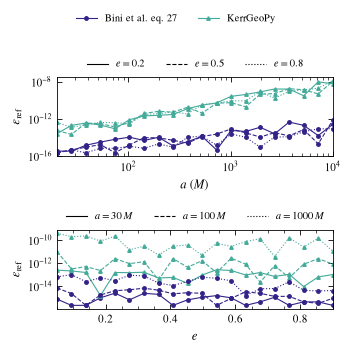

In [30]:
EVALUATIONS = dict(
    ours=dict(color=COLORS[0], marker="o", label="Bini et al. eq. 27"),
    kerrgeopy=dict(color=COLORS[2], marker="^", label="KerrGeoPy"),
)
LINESTYLES = ("-", "--", ":")

fig, (ax_a, ax_e) = new_figure(PAPER_WIDTH, height=88, nrows=2)
floor = np.finfo(float).eps
for ax, x, exact, curves, label, xlabel in (
    (ax_a, a_grid, exact_a, e_values, lambda e: rf"$e={e}$", r"$a$ ($M$)"),
    (ax_e, e_grid, exact_e, a_values, lambda a: rf"$a={a}\,M$", r"$e$"),
):
    for ls, curve in zip(LINESTYLES, curves):
        for key, kw in EVALUATIONS.items():
            ax.plot(x, np.maximum(exact[curve][key], floor), ls=ls, ms=2.5, lw=0.8,
                    color=kw["color"], marker=kw["marker"])
        ax.plot([], [], color="k", ls=ls, lw=0.8, label=label(curve))
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncols=3, frameon=False, borderaxespad=0.3)
    ax.set(xlabel=xlabel, ylabel=r"$\varepsilon_{\rm ref}$", yscale="log", xlim=(x.min(), x.max()))
ax_a.set(xscale="log")

handles = [plt.Line2D([], [], ms=2.5, lw=0.8, color=kw["color"], marker=kw["marker"], label=kw["label"])
           for kw in EVALUATIONS.values()]
fig.legend(handles=handles, loc="outside upper center", ncols=2, frameon=False, borderpad=0.8)
plt.show()


Monte Carlo sample for the comparison: `100` random equatorial prograde orbits at $\chi=0.9$, each integrated once by both codes with `rtol=1e-12` / `goal=12` (`measure_precession` of section 3.1).

* $a$: log-uniform in $[30,\,10^4]\,M$
* $e$: uniform in $[0.05,\,0.9]$
* fixed seed (`2026`), so the sample is reproducible
* $a\geq30\,M$ keeps every orbit above the separatrix ($p\geq5.7\,M$ at $e=0.9$, as in section 3.1)

In [31]:
rng = np.random.default_rng(2026)
n_orbits = 100
mc_a = np.exp(rng.uniform(np.log(30), np.log(1e4), n_orbits))    # log-uniform a [M]
mc_e = rng.uniform(0.05, 0.9, n_orbits)

monte_carlo = Table(rows=[measure_precession(bh, a*bh.r_g, e, rtol=1e-12, goal=12) for a, e in zip(mc_a, mc_e)])
monte_carlo["a"] = mc_a
monte_carlo["e"] = mc_e

Figure for the paper, the same `100` orbits seen against $a$ (a) and against $e$ (b), for the three libraries:

* rows of the work–precision run (section 3.3, `data/work-precision/`): same orbits (`orbit_id` = index in cell 57), same $\varepsilon$
* each library with the integrator of lowest median $\varepsilon$ at the same nominal tolerance $10^{-12}$:
  * Relatipy `dp45` (100 orbits: `dp45` $1.0\times10^{-8}$, `radau` $4.9\times10^{-7}$, `projection_radau` $5.0\times10^{-7}$, `dop853` $2.8\times10^{-6}$)
  * PyGRO `dp45` (20-orbit pilot of its five integrators, section 3.3)
  * GYOTO `runge_kutta_dopri5`, the same scheme (20-orbit pilot of its integrators, section 3.3)
* orbits grouped in `8` bins of the horizontal variable (log-spaced in $a$, linear in $e$), each at the median of its orbits
* marker: median $\varepsilon$ in each bin; error bar: $2\sigma$ interval of that median (bootstrap, as in section 3.3), not the spread of the orbits
* the three libraries are shifted slightly in $x$ so that the error bars of one bin do not overlap; Relatipy drawn on top

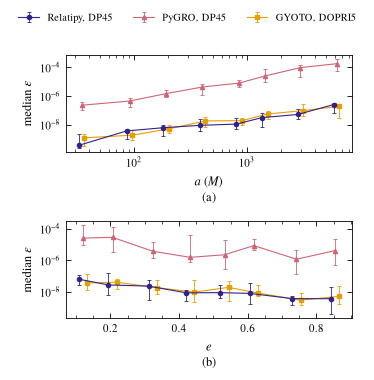

library,median_eps,max_eps
str14,float64,float64
"Relatipy, DP45",1.0157558738566053e-08,1.2484209819252357e-06
"PyGRO, DP45",5.992537961185818e-06,0.0013811132279144545
"GYOTO, DOPRI5",1.6006411862612424e-08,5.609462279121402e-07


In [4]:
from astropy.table import vstack

comparison_rows = vstack([
    Table.read("data/work-precision/work-precision.csv"),
    Table.read("data/work-precision/work-precision-gyoto.csv"),
])
LIBRARIES = {    # label: library, method, nominal tolerance (PyGRO stores goal), color, marker, side shift
    "Relatipy, DP45": dict(library="relatipy", method="dp45", tol=1e-12, color=COLORS[0], marker="o", shift=-1),
    "PyGRO, DP45": dict(library="pygro", method="dp45", tol=12, color=COLORS[1], marker="^", shift=0),
    "GYOTO, DOPRI5": dict(library="gyoto", method="runge_kutta_dopri5", tol=1e-12, color="#E69F00", marker="s", shift=1),
}
TWO_SIGMA = (2.275, 97.725)    # [%] two-sided 2 sigma of a normal distribution
rng = np.random.default_rng(2026)

best = {}
for label, kw in LIBRARIES.items():
    rows = comparison_rows[
        (comparison_rows["library"] == kw["library"])
        & (comparison_rows["method"] == kw["method"])
        & np.isclose(comparison_rows["tol"], kw["tol"], rtol=1e-6, atol=0)
    ]
    rows.sort("orbit_id")
    assert len(rows) == n_orbits and np.all(rows["status"] == "ok"), label
    best[label] = rows


def binned_median(x, y, edges, n_boot=2000):
    """Median x, median y and the 2 sigma bootstrap interval of that median, in each bin of x that holds orbits."""
    index = np.digitize(x, edges[1:-1])
    bins = [index == i for i in range(edges.size - 1) if np.any(index == i)]
    interval = [np.percentile(np.median(rng.choice(y[b], (n_boot, b.sum())), axis=1), TWO_SIGMA) for b in bins]
    return dict(
        x=np.array([np.median(x[b]) for b in bins]),
        median=np.array([np.median(y[b]) for b in bins]),
        low=np.array([low for low, _ in interval]),
        high=np.array([high for _, high in interval]),
    )


# Plot
fig, axes = new_figure(PAPER_WIDTH, height=95, nrows=2)
for ax, (tag, column, edges, xlabel, xscale, shifted) in zip(axes, (
    ("(a)", "a", np.geomspace(30, 1e4, 9), r"$a$ ($M$)", "log", lambda x, k: x * 1.06**k),
    ("(b)", "e", np.linspace(0.05, 0.9, 9), r"$e$", "linear", lambda x, k: x + 0.012 * k),
)):
    for label, kw in LIBRARIES.items():
        rows = best[label]
        b = binned_median(rows[column].data, rows["eps"].data, edges)
        ax.errorbar(
            shifted(b["x"], kw["shift"]), b["median"],
            yerr=[b["median"] - b["low"], b["high"] - b["median"]],
            color=kw["color"], marker=kw["marker"], ms=3, lw=0.8,
            elinewidth=0.6, capsize=1.5, capthick=0.6, label=label,
            zorder=3 if kw["library"] == "relatipy" else 2,    # Relatipy on top
        )
    ax.set(xscale=xscale, yscale="log", xlabel=xlabel + "\n" + tag, ylabel=r"median $\varepsilon$")

fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=3, frameon=False, borderpad=0.8)
save_paper_figure(fig, "precession", "precession-comparison")
plt.show()

Table(rows=[
    dict(
        library=label,
        median_eps=np.median(rows["eps"]),
        max_eps=rows["eps"].max(),
    )
    for label, rows in best.items()
])


### 3.3. Work–precision

Cost of the same measurement at several tolerances: median $\varepsilon$ of section 3.1 against the median wall time of one integration, over the `100` Monte Carlo orbits of section 3.2.

* Relatipy: its four methods, `"projection_radau"`, `"radau"`, `"dop853"` and `"dp45"`, `rtol` $\in\{10^{-6},10^{-8},10^{-10},10^{-12},10^{-13}\}$, default `atol`
* PyGRO: `rkf78` and `dp45`, `goal` $\in\{6,8,10,12\}$; its engine compilation (once per $\chi$ and integrator, 12 s) is not counted
* the two PyGRO integrators are the best of a 20-orbit pilot of all five: `dp45` reaches the smallest $\varepsilon$ and `rkf78` the lowest cost at intermediate $\varepsilon$; `dp853` and `rkf45` cost more for the same $\varepsilon$, and `ck45` fails in PyGRO 1.0.3 (`AttributeError: 'CashKarp45' object has no attribute 'verbose'`)
* GYOTO ([Vincent et al. 2011](https://doi.org/10.1088/0264-9381/28/22/225011)): `Star` in `KerrBL`, `runge_kutta_fehlberg78` (its default) and `runge_kutta_dopri5`, `RelTol` $=$ `AbsTol` $\in\{10^{-6},10^{-8},10^{-10},10^{-12},10^{-13}\}$
  * `DeltaMaxOverR=1e10`: the default `1` caps each step at $r$, which then sets the step instead of the tolerance
  * GYOTO stops at a coordinate time: it is given the coordinate time of the Relatipy orbit at the same proper time (`dop853`, `rtol=1e-13`)
  * run by `data/work-precision/work_precision_gyoto.py` with the Python where GYOTO is built, from the initial states written by `work_precision.py --dump-states`; GYOTO compiled from its GitHub repository
  * of the five GYOTO integrators (20-orbit pilot): `runge_kutta_dopri5` reaches the smallest $\varepsilon$; `runge_kutta_cash_karp54` (and its `_classic` variant, identical) costs about the same; `Legacy` does not compute proper time and ignores `RelTol`
* KerrGeoPy: no integration, so no $\varepsilon$ comparable with the others; shown as a band, the range of its time per orbit (minimum to maximum over the `100` orbits) for `kg.StableOrbit` and `fundamental_frequencies`, the closed-form advance of section 3.2; run by `data/work-precision/work_precision_kerrgeopy.py` (KerrGeoPy 0.9.3, same core and protocol)
* time: the solve call only, one core (`taskset`, BLAS/OpenMP threads set to 1), best of 3 repeats per orbit, after one warm-up solve
* run by `data/work-precision/work_precision.py` (helpers copied from cells 4, 6, 43, 45 and 57; 16 min); its rows are read back here
* error bars: $2\sigma$ interval of each median (percentiles 2.275 and 97.725 of `2000` bootstrap resamples of the orbits, seed `2026`), in $\varepsilon$ and in time; the uncertainty of the median, not the spread of the orbits, which covers several decades
* end labels: `rtol` (Relatipy) or $10^{-\texttt{goal}}$ (PyGRO) at both ends of one line per group of lines
* `status`: `ok`, or a failed integration: Relatipy `projection_radau` stops with "invariant projection failed" at loose tolerances; PyGRO drifts into its horizon stop (`rkf78` at `goal` $\le8$, `dp45` at `goal=6`). An orbit that ends with fewer than two pericentres has no $\varepsilon$ (one orbit of PyGRO `dp45` at `goal=6`, stopped with no error). Medians use only the `ok` orbits with a measured $\varepsilon$; the settings with failures are listed here, not marked in the figure

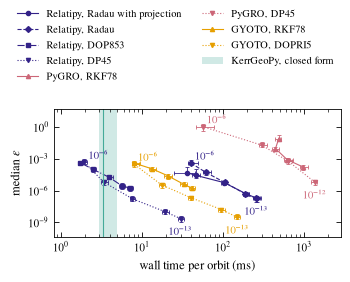

library,method,tol,n_ok,wall_s,wall_low,wall_high,eps,eps_low,eps_high
str8,str22,float64,int64,float64,float64,float64,float64,float64,float64
relatipy,projection_radau,1e-13,100,0.26481517200045346,0.24426651199974003,0.29103531400323845,1.792681931789275e-07,8.750851243632951e-08,2.56495758577668e-07
relatipy,projection_radau,1e-12,100,0.19251447349961381,0.1779415089986287,0.209730018999835,4.97835871637875e-07,3.0129748518348265e-07,7.796894623268713e-07
relatipy,projection_radau,1e-10,87,0.10362361100123962,0.09496424700046191,0.11024219399769208,5.540503079881631e-06,4.09669217027453e-06,8.458591180593444e-06
relatipy,projection_radau,1e-08,39,0.045911186000012094,0.04129227900193655,0.05226496499744826,2.7557260752875123e-05,1.6231969691249404e-05,0.0001034789951394055
relatipy,projection_radau,1e-06,14,0.03560524449858349,0.02504700600002252,0.04505584450089373,4.994418306752957e-05,3.8061426125945985e-05,0.00015886520850738606
relatipy,radau,1e-13,100,0.25959863100069924,0.23811649800154555,0.28553176983067025,1.7934022222831913e-07,8.793443484478303e-08,2.6352003359501855e-07
relatipy,radau,1e-12,100,0.187958599999547,0.1749931325911807,0.2069606240002031,4.868453388207072e-07,2.9780379713184586e-07,7.9223786042526e-07
relatipy,radau,1e-10,100,0.10530416649817198,0.09977083321722967,0.11287857800198253,5.769134089395056e-06,4.2549658405555135e-06,8.599108999529648e-06
relatipy,radau,1e-08,100,0.06138795149854559,0.05609916550019989,0.07060535949858604,5.176161957953784e-05,2.6998204488259958e-05,8.587923158392963e-05


In [3]:
from astropy.table import vstack

work_precision = vstack([
    Table.read("data/work-precision/work-precision.csv"),
    Table.read("data/work-precision/work-precision-gyoto.csv"),
])
kerrgeopy_wall = Table.read("data/work-precision/work-precision-kerrgeopy.csv")["wall_s"].data * 1e3    # [ms]
pygro_rows = work_precision["library"] == "pygro"
work_precision["tol"][pygro_rows] = 10.0**-work_precision["tol"][pygro_rows]    # PyGRO rows store goal: atol = rtol = 10**-goal
GYOTO_COLOR = "#E69F00"    # Okabe-Ito orange: COLORS has no free colour distinct from the other libraries
SETTINGS = {    # color: library; marker and line: method; tolerances written at both ends of one line per group
    ("relatipy", "projection_radau"): dict(label="Relatipy, Radau with projection", color=COLORS[0], marker="o"),
    ("relatipy", "radau"): dict(label="Relatipy, Radau", color=COLORS[0], marker="D", ls="--", annotate=True),
    ("relatipy", "dop853"): dict(label="Relatipy, DOP853", color=COLORS[0], marker="s", ls="-."),
    ("relatipy", "dp45"): dict(label="Relatipy, DP45", color=COLORS[0], marker="v", ls=":", annotate=True),
    ("pygro", "rkf78"): dict(label="PyGRO, RKF78", color=COLORS[1], marker="^"),
    ("pygro", "dp45"): dict(label="PyGRO, DP45", color=COLORS[1], marker="v", ls=":", annotate=True),
    ("gyoto", "runge_kutta_fehlberg78"): dict(label="GYOTO, RKF78", color=GYOTO_COLOR, marker="^"),
    ("gyoto", "runge_kutta_dopri5"): dict(label="GYOTO, DOPRI5", color=GYOTO_COLOR, marker="v", ls=":", annotate=True),
}

TWO_SIGMA = (2.275, 97.725)    # [%] two-sided 2 sigma of a normal distribution
rng = np.random.default_rng(2026)


def median_interval(values, n_boot=2000):
    """2 sigma bootstrap interval of the median."""
    medians = np.median(rng.choice(values, (n_boot, values.size)), axis=1)
    return np.percentile(medians, TWO_SIGMA)


summary = []
for (library, method), kw in SETTINGS.items():
    rows = work_precision[(work_precision["library"] == library) & (work_precision["method"] == method)]
    for tol in np.unique(rows["tol"]):
        ok = rows[(rows["tol"] == tol) & (rows["status"] == "ok") & np.isfinite(rows["eps"])]    # ok and measured
        wall, eps = ok["wall_s"].data, ok["eps"].data
        summary.append((library, method, tol, len(ok), np.median(wall), *median_interval(wall),
                        np.median(eps), *median_interval(eps)))
summary = Table(rows=summary, names=("library", "method", "tol", "n_ok", "wall_s", "wall_low", "wall_high",
                                     "eps", "eps_low", "eps_high"))

fig, ax = new_figure(PAPER_WIDTH, height=70)
for (library, method), kw in SETTINGS.items():
    s = summary[(summary["library"] == library) & (summary["method"] == method)]
    ax.plot(s["wall_s"] * 1e3, s["eps"], color=kw["color"], ls=kw.get("ls", "-"), lw=0.8, label=kw["label"],
            marker=kw["marker"], ms=3)
    ax.errorbar(s["wall_s"] * 1e3, s["eps"], color=kw["color"], fmt="none", elinewidth=0.6, capsize=1.5,
                capthick=0.6, xerr=[(s["wall_s"] - s["wall_low"]) * 1e3, (s["wall_high"] - s["wall_s"]) * 1e3],
                yerr=[s["eps"] - s["eps_low"], s["eps_high"] - s["eps"]])
    # tolerance at both ends of the line: tightest below its point, loosest above right
    ends = [(s[0], dict(xytext=(0, -5), ha="center", va="top")), (s[-1], dict(xytext=(3, 2)))]
    for row, place in ends if kw.get("annotate") else []:
        ax.annotate(rf"$10^{{{np.log10(row['tol']):.0f}}}$", (row["wall_s"] * 1e3, row["eps"]),
                    textcoords="offset points", fontsize=STYLE.target.small_size, color=kw["color"], **place)
# KerrGeoPy: closed form, no epsilon; band over the range of its time per orbit, line at the median
ax.axvspan(kerrgeopy_wall.min(), kerrgeopy_wall.max(), color=COLORS[2], alpha=0.25, lw=0,
           label="KerrGeoPy, closed form")
ax.axvline(np.median(kerrgeopy_wall), color=COLORS[2], lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="wall time per orbit (ms)", ylabel=r"median $\varepsilon$")
ax.margins(x=0.1, y=0.15)    # room for the end labels
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncols=2, frameon=False)
save_paper_figure(fig, "precession", "work-precision")
plt.show()
summary

## 4. Orbital fit of S2 with MCMC

The S2 orbital fit of PyGRO's documentation ([Della Monica 2025](https://doi.org/10.1051/0004-6361/202554300)), run with three forward models and the same sampler, priors, likelihood and data:

* data: astrometry (`145` epochs) and line-of-sight velocities (`44` epochs) of S2 from [Gillessen et al. 2017](https://doi.org/10.3847/1538-4357/aa5c41), as distributed with PyGRO
* `13` parameters: $D$, $M$, $t_p$, $a$, $e$, $i$, $\Omega$, $\omega$ and five reference-frame parameters $x_0$, $y_0$, $v_{x,0}$, $v_{y,0}$, $v_{\rm LSR}$
* priors and starting values: those of PyGRO's script (flat for the first eight, Gaussian for the frame parameters)
* spacetime: Schwarzschild ($\chi=0$), Rømer delay included
* sampler: `emcee` ([Foreman-Mackey et al. 2013](https://doi.org/10.1086/670067)), `32` walkers, the same initial walkers for the three codes, `multiprocessing.Pool` with `16` processes
* forward models:
  * Relatipy: `KerrMcmcModel`, `method="dop853"`
  * PyGRO: the original script, `integrator="dp45"`, `accuracy_goal=15`, `precision_goal=15`
  * KerrGeoPy: analytic Mino-time geodesic, observed time solved by Newton iterations
* machine: AMD Ryzen AI 7 350 (8 cores, 16 threads)

Two runs, both in `thesis/pruebas/comparacion/`:

| Run | Date | Relatipy setup | Used for |
|---|---|---|---|
| `004` | 2026-10-18 | osculating Keplerian elements at pericentre, `rtol=1e-6`, `atol=1e-9`; seed `20261018` | cost (4.1); KerrGeoPy and PyGRO posteriors (4.2) |
| `005` | 2026-10-24 | exact radial turning points (`bound` orbit, PyGRO's definition of $a$ and $e$), `rtol=1e-9`, `atol=1e-12` | Relatipy posterior (4.2) |

* run `004`: Relatipy does the `300000` steps of PyGRO's script; PyGRO and KerrGeoPy then run for the same wall time (1 h 29 min each)
* run `005`: Relatipy alone, `300000` steps

### 4.1. Cost

Run `004`:

| Library | Steps done | Time per step [s] | Steps relative to Relatipy | One evaluation, serial [ms] | Acceptance |
|---|---|---|---|---|---|
| Relatipy | `300000` | `0.0179` | `1` | `2.6` | `0.334` |
| KerrGeoPy | `79763` | `0.0673` | `0.266` | `14` | `0.345` |
| PyGRO | `3365` | `1.595` | `0.0112` | `318` | `0.352` |

* in the same wall time, Relatipy completes `89` times more steps than PyGRO and `3.8` times more than KerrGeoPy
* longest integrated autocorrelation time $\tau$: `252` (Relatipy), `245` (KerrGeoPy) and `229` (PyGRO) steps
* chain length in units of $\tau$: about `1190` (Relatipy), `325` (KerrGeoPy) and `15` (PyGRO); the `emcee` documentation asks for more than `50` $\tau$, so the PyGRO chain is not converged
* run `005` (tighter tolerance, turning-point elements): `0.0253` s per step, `300000` steps in 2 h 07 min, $\tau_{\max}=251$; about `2.8` % of the model evaluations needed a retry (DOP853 step underflow in that version)

### 4.2. Posterior against Gillessen et al. 2017 and PyGRO

Median and 16–84 % interval of each parameter, after discarding $3\tau_{\max}$ steps and thinning by $\tau_{\min}/2$:

| Parameter | [Gillessen et al. 2017](https://doi.org/10.3847/1538-4357/aa5c41) | [PyGRO documentation](https://rdellamonica.github.io/pygro/examples/S2_MCMC.html) | Relatipy | KerrGeoPy | PyGRO (this run) |
|---|---|---|---|---|---|
| $D$ [kpc] | $8.33\pm0.12$ | $8.29\pm0.17$ | $8.333^{+0.077}_{-0.071}$ | $8.332^{+0.078}_{-0.070}$ | $8.334^{+0.077}_{-0.064}$ |
| $M$ [$10^6M_\odot$] | $4.35\pm0.13$ | $4.29\pm0.19$ | $4.337^{+0.083}_{-0.073}$ | $4.337^{+0.082}_{-0.072}$ | $4.336^{+0.083}_{-0.072}$ |
| $t_p$ [yr] | $2002.33\pm0.01$ | $2002.325\pm0.005$ | $2002.3213^{+0.0036}_{-0.0037}$ | $2002.3214^{+0.0035}_{-0.0036}$ | $2002.3210\pm0.0035$ |
| $a$ [arcsec] | $0.1255\pm0.0009$ | $0.1250\pm0.0009$ | $0.12458^{+0.00056}_{-0.00055}$ | $0.12458^{+0.00057}_{-0.00054}$ | $0.12452^{+0.00054}_{-0.00052}$ |
| $e$ | $0.8839\pm0.0019$ | $0.8830\pm0.0018$ | $0.88230^{+0.00136}_{-0.00138}$ | $0.88230^{+0.00137}_{-0.00134}$ | $0.88215^{+0.00138}_{-0.00129}$ |
| $i$ [deg] | $134.18\pm0.40$ | $134.72\pm0.40$ | $134.80\pm0.28$ | $134.81^{+0.28}_{-0.29}$ | $134.82\pm0.27$ |
| $\Omega$ [deg] | $226.94\pm0.60$ | $227.28\pm0.59$ | $227.16^{+0.49}_{-0.48}$ | $227.17^{+0.49}_{-0.48}$ | $227.13^{+0.45}_{-0.47}$ |
| $\omega$ [deg] | $65.51\pm0.57$ | $65.39\pm0.57$ | $65.26\pm0.42$ | $65.27\pm0.42$ | $65.23^{+0.40}_{-0.42}$ |

* Gillessen et al. 2017: $D$ and $M$ from their Keplerian fit of the combined S2 data with coordinate-system priors; orbital elements from their table of S-star orbits, row S2
* Relatipy: run `005`; $a$ and $e$ defined as in PyGRO, with $r_p=a(1-e)$ and $r_a=a(1+e)$ the exact radial turning points. Against the PyGRO documentation, every parameter is within $0.8\sigma$ (largest: $t_p$, $0.74\sigma$; $a$, $0.46\sigma$; the others $\le0.4\sigma$, in units of the documented error)
* KerrGeoPy: run `004`, started from the osculating Keplerian state at pericentre; $a$ and $e$ converted sample by sample to PyGRO's definition (`004/convert_elements.py`, exact for $\chi=0$: $r_a$ from the cubic radial potential with the sample's $E$ and $L$), result in `004/results/elements_pygro_definition.csv`; differs from Relatipy by $<0.01\sigma$
* PyGRO documentation: results of the same S2 fit reported by PyGRO's authors for a chain run to convergence (best fit and error as given there)
* PyGRO (this run): chain not converged (`15` $\tau$, section 4.1); listed for completeness, not used as reference. The reference for PyGRO is its documentation column

| param | paper | relatipy | kerrgeopy | pygro |
|---|---|---|---|---|
| t_p [yr] | 2023.126 ± 0.010 | 2023.1196 ± 0.0007 | 2023.1196 ± 0.0007 | 2023.1196 ± 0.0007 |
| a [mas]* | 83.0 ± 0.7 | 46.06 ± 0.05 | 46.06 ± 0.05 | 46.05 ± 0.05 |
| e* | 0.9832 ± 0.0010 | 0.96862 ± 0.00009 | 0.96863 ± 0.00008 | 0.96865 ± 0.00008 |
| i [°] | 124.09 ± 1.10 | 123.28 ± 0.07 | 123.28 ± 0.08 | 123.27 ± 0.09 |
| Ω [°] | 73.8 ± 3.5 | 75.98 ± 0.16 | 75.98 ± 0.17 | 75.98 ± 0.23 |
| ω [°] | 293.4 ± 2.2 | 295.65 ± 0.08 | 295.66 ± 0.08 | 295.66 ± 0.15 |
| χ | — | 0.41 ± 0.24 | 0.40 ± 0.24 | 0.52 ± 0.29 |
| χ² | 25.86 | 29.2 | 29.3 | 31.1 |
| pasos corridos / configurados | — | 20 / 20 | 20 / 20 | 3 / 20 † |

\* a y e en convención osculante newtoniana, no comparables directo con el paper.
† pygro cortado por límite de tiempo del modo `quick`.
Errores ± = (p84 − p16)/2; cadenas no convergidas, errores no reales.


## 5. Field of a thin disk

Relatipy adds a Newtonian acceleration to the Kerr geodesic equation. The built-in force is a razor-thin power-law disk (`rp.ThinDisk`). This section reproduces Fig. 3 of [Foschi et al. 2026](https://arxiv.org/abs/2607.26713): the disk acceleration in the disk plane and along its axis, normalised by the black-hole acceleration.

Surface density (eq. 13):

$$\Sigma(r)=\frac{B}{r^{\gamma}}$$

Total mass between $r_{\rm min}$ and $r_{\rm max}$ (eq. 16):

$$M_{\rm tot}=2\pi\int_{r_{\rm min}}^{r_{\rm max}}Br'^{1-\gamma}dr'=2\pi\begin{cases}\dfrac{B(r_{\rm min}^{2-\gamma}-r_{\rm max}^{2-\gamma})}{\gamma-2}&\gamma\neq2\\[1ex]B\log\left(\dfrac{r_{\rm max}}{r_{\rm min}}\right)&\gamma=2\end{cases}$$

Acceleration, summed over rings of mass $dM=2\pi Br'^{1-\gamma}dr'$ (eqs. 14, 15 and 17):

$$da_d^{\rm disk}=-\frac{G\,dM}{\pi p}\left[\frac{K(k)}{d^2}+\left(1-\frac{z^2+R^2}{d^2}\right)\frac{E(k)}{q^2}\right]d$$

$$da_z^{\rm disk}=-\frac{2G\,dM}{\pi pq^2}E(k)\,z$$

$$\mathbf a_{\rm disk}=\int_{r_{\rm min}}^{r_{\rm max}}da_d^{\rm disk}\,\mathbf u_d+da_z^{\rm disk}\,\mathbf u_z$$

with (eqs. 6 and 7)

$$p=\sqrt{(d+R)^2+z^2},\qquad q=\sqrt{(d-R)^2+z^2},\qquad k=\frac{4Rd}{p^2}$$

* $d$, $z$: cylindrical radius and height of the field point; $\mathbf u_d$, $\mathbf u_z$: unit vectors along them
* $R$: ring radius, the integration variable $r'$
* $K$, $E$: complete elliptic integrals with parameter $k$ (`scipy.special.ellipk`, `ellipe`)

Normalisation (Sect. 2.2.2, text before Fig. 3), with $M_\bullet=4.29\times10^6\,M_\odot$ (eq. 40):

$$|\mathbf a_{\rm BH}|=\frac{GM_\bullet}{r^2}$$

Setup of Fig. 3: $M_{\rm tot}=10^3\,M_\odot$, $r_{\rm min}=10^{-6}$ pc, $r_{\rm max}=1$ pc, $\gamma=1$ and $2$. Not reproduced: the Plummer curve, because the paper gives only $r_0$ and $\rho_0$, not the formula.

Evaluation of the quadrature on the two lines of Fig. 3:

* axis ($d=0$): eq. 15 with $k=0$; the $d$ component vanishes by symmetry
* plane ($z=0$, $r_{\rm min}<d<r_{\rm max}$): the bracket of eq. 14 goes as $1/(d-R)$, so the integral is a principal value; it is taken by pairing $R=d\pm s$
* $K(k)$ is evaluated as `ellipkm1(1 - k)` with $1-k=q^2/p^2$, to keep precision next to the ring

Relatipy's disk (docstring of `ThinDisk`):

* $\Sigma\propto R^{\alpha}$ between `r_in` and `r_out`, so `slope` $=\alpha=-\gamma$
* every ring of radius $R'$ softened with $H=\epsilon R'$ (`softening=`, default $\epsilon=10^{-2}$); Foschi's disk is not softened, so the difference must shrink as $\epsilon\to0$
* the field is read with the private evaluator `relatipy._force_core.acceleration`, as in the test suite

Relative difference:

$$\varepsilon_a=\frac{|\mathbf a_{\rm Relatipy}-\mathbf a_{\rm Foschi}|}{|\mathbf a_{\rm Foschi}|}$$

In [3]:
from relatipy import _force_core
from scipy.special import ellipe, ellipkm1

M_BH = 4.29e6 * u.Msun    # Foschi et al., eq. 40
PARSEC = (u.pc / rp.Kerr(mass=M_BH, spin=0.0).r_g).to_value(u.one)    # M per pc
FIG3 = dict(
    M_tot=(1e3 * u.Msun / M_BH).to_value(u.one),
    r_min=1e-6 * PARSEC,
    r_max=1.0 * PARSEC,
)
QUAD = dict(limit=1000, epsabs=0, epsrel=1e-10)


def foschi_disk_acceleration(points, M_tot, r_min, r_max, gamma):
    """Acceleration of the zero-thickness disk at Cartesian points [M]: Foschi et al. 2026, eqs. 14-17 (G = 1)."""
    if gamma == 2:
        B = M_tot / (2*np.pi * np.log(r_max / r_min))    # eq. 16
    else:
        B = M_tot * (gamma - 2) / (2*np.pi * (r_min**(2 - gamma) - r_max**(2 - gamma)))    # eq. 16

    def ring(R, d, z, component):
        p = np.sqrt((d + R)**2 + z**2)    # eq. 6
        q2 = (d - R)**2 + z**2
        k = 4 * R * d / p**2              # eq. 7
        dM = 2*np.pi * B * R**(1 - gamma)
        if component == "d":
            K = ellipkm1(q2 / p**2)       # K(k), with 1 - k = q^2 / p^2
            return -dM / (np.pi * p) * (K / d**2 + (1 - (z**2 + R**2) / d**2) * ellipe(k) / q2) * d    # eq. 14
        return -2 * dM / (np.pi * p * q2) * ellipe(k) * z    # eq. 15

    def radial(d, z):
        if d == 0:
            return 0.0
        if z != 0 or not r_min < d < r_max:
            breaks = [d] if r_min < d < r_max else None
            return quad(ring, r_min, r_max, args=(d, z, "d"), points=breaks, **QUAD)[0]
        h = min(d - r_min, r_max - d, d / 2)
        pairs = quad(lambda s: ring(d + s, d, 0.0, "d") + ring(d - s, d, 0.0, "d"), 0, h, **QUAD)[0]
        inner = quad(ring, r_min, d - h, args=(d, 0.0, "d"), **QUAD)[0] if d - h > r_min else 0.0
        outer = quad(ring, d + h, r_max, args=(d, 0.0, "d"), **QUAD)[0] if d + h < r_max else 0.0
        return inner + pairs + outer

    rows = []
    for x, y, z in points:
        d = np.hypot(x, y)
        a_d = radial(d, z)
        breaks = sorted({s for s in (d, np.hypot(d, z)) if r_min < s < r_max}) or None    # ring through the point; scale of the axis kernel
        a_z = quad(ring, r_min, r_max, args=(d, z, "z"), points=breaks, **QUAD)[0] if z != 0 else 0.0
        rows.append((a_d * x / d if d else 0.0, a_d * y / d if d else 0.0, a_z))
    return np.array(rows)


def relatipy_disk_acceleration(disk, points):
    """Acceleration of a Relatipy disk bound to M_BH at Cartesian points [M] of the black-hole frame (G = M = 1)."""
    bound = disk._bind(M_BH)
    return _force_core.acceleration(
        bound.callback, bound.model, np.ascontiguousarray(points), np.zeros_like(points))

Grid as in Fig. 3: $8\times10^{-5}\le r\le5$ pc, in the plane ($r=d$, $z=0$) and on the axis ($r=z$, $d=0$). With $G=M_\bullet=1$, $|\mathbf a|/|\mathbf a_{\rm BH}|=|\mathbf a|\,r^2$. Relatipy with $\epsilon=10^{-2}$, $10^{-3}$ and $10^{-4}$.

In [4]:
r_fig3 = np.geomspace(8e-5, 5, 61) * PARSEC
LINES = dict(
    plane=np.stack([r_fig3, 0 * r_fig3, 0 * r_fig3], axis=1),
    axis=np.stack([0 * r_fig3, 0 * r_fig3, r_fig3], axis=1),
)
gammas = (1, 2)
softenings = (1e-2, 1e-3, 1e-4)

fig3_exact, fig3_library, fig3_error = {}, {}, {}
for gamma in gammas:
    for line, points in LINES.items():
        exact = foschi_disk_acceleration(points, gamma=gamma, **FIG3)
        fig3_exact[gamma, line] = np.linalg.norm(exact, axis=1) * r_fig3**2
        for eps in softenings:
            disk = rp.ThinDisk(
                mass=1e3 * u.Msun,
                r_in=1e-6 * u.pc,
                r_out=1 * u.pc,
                slope=-float(gamma),
                softening=eps,
            )
            library = relatipy_disk_acceleration(disk, points)
            fig3_library[gamma, line, eps] = np.linalg.norm(library, axis=1) * r_fig3**2
            fig3_error[gamma, line, eps] = (
                np.linalg.norm(library - exact, axis=1) / np.linalg.norm(exact, axis=1))

Figure: (a) plane and (c) axis, $|\mathbf a_{\rm disk}|/|\mathbf a_{\rm BH}|$ from Foschi's quadrature (lines) and Relatipy at the default $\epsilon$ (circles); (b) and (d), $\varepsilon_a$ of Relatipy against Foschi at the default $\epsilon$. Colour: $\gamma$. Grey line: $r_{\rm max}$.

In [5]:
GAMMA_COLORS = {1: COLORS[0], 2: COLORS[1]}
EPS = softenings[0]
every = 3

fig, blocks = stacked_blocks(height=135, ratios=(2, 1), gap=0.25)
for (ax_a, ax_e), line, tags, (coordinate, variable) in zip(
        blocks, LINES, ("ab", "cd"), (("z=0", "d"), ("d=0", "z"))):
    for gamma, color in GAMMA_COLORS.items():
        ax_a.plot(r_fig3 / PARSEC, fig3_exact[gamma, line], color=color)
        ax_a.plot(r_fig3[::every] / PARSEC, fig3_library[gamma, line, EPS][::every], ls="none", marker="o", ms=2.5,
                  mfc="none", color=color)
        ax_e.plot(r_fig3 / PARSEC, fig3_error[gamma, line, EPS], color=color)
    ax_a.set(ylabel=r"$|\mathbf{a}_{\rm disk}|/|\mathbf{a}_{\rm BH}|$", yscale="log")
    ax_e.set(ylabel=r"$\varepsilon_a$", yscale="log", xlabel=rf"${variable}$ (pc)", xscale="log",
             xlim=(r_fig3.min() / PARSEC, r_fig3.max() / PARSEC))
    for ax, tag, (x, ha) in zip((ax_a, ax_e), tags, ((0.98, "right"), (0.02, "left"))):
        ax.axvline(1.0, color="0.6", lw=0.4)
        ax.text(x, 0.06, rf"({tag}) ${coordinate}$", transform=ax.transAxes, ha=ha, va="bottom", fontsize=TAG_SIZE)
# Colour: gamma; line and circles: Foschi et al. and Relatipy
handles = [
    *[plt.Line2D([], [], color=color, lw=3, label=rf"$\gamma={gamma}$") for gamma, color in GAMMA_COLORS.items()],
    plt.Line2D([], [], color="k", label="Foschi et al."),
    plt.Line2D([], [], color="k", ls="none", marker="o", ms=2.5, mfc="none", label="Relatipy"),
]
fig.legend(handles=handles, loc="outside upper center", ncols=2, frameon=False, borderpad=0.8)

glue_panels(fig, groups=blocks)
save_paper_figure(fig, 'thin-disk', 'foschi-fig3')
plt.show()

/tmp/ipykernel_592528/3174127241.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Convergence with the softening, $\max_r\varepsilon_a$ on each line:

In [6]:
Table(rows=[
    (gamma, line, *[fig3_error[gamma, line, eps].max() for eps in softenings])
    for gamma in gammas for line in LINES
], names=["gamma", "line", *[f"eps={eps:g}" for eps in softenings]])

gamma,line,eps=0.01,eps=0.001,eps=0.0001
int64,str5,float64,float64,float64
1,plane,0.004516317701716066,4.622175296160731e-05,4.6227791941033707e-07
1,axis,5.062896551348669e-05,5.063274987740068e-07,7.217155117233723e-09
2,plane,0.0020971568127528778,0.00020971737378010558,2.0965574209863075e-05
2,axis,1.225881278098584e-05,1.1966700106658143e-07,6.681045555840436e-09


Reading (grey line: $r_{\rm max}$):

* (a), (c): Relatipy reproduces both curves of Fig. 3 of Foschi et al., including the peak at $d=r_{\rm max}$ in the plane, the growth $\propto r$ inside the disk and the common limit beyond $r_{\rm max}$
* the difference is set by the softening: on the axis and for $\gamma=1$ in the plane, $\varepsilon_a\propto\epsilon^2$; for $\gamma=2$ in the plane, $\varepsilon_a\propto\epsilon$ (table)
* (b): largest difference at $d=r_{\rm max}$, where the unsoftened field diverges

\subsection{Adición de fuerza generalizada

Para incluir el efecto de un disco sobre la órbita partimos de la ecuación de
la geodésica forzada en Kerr, tal como la escriben \citet{Gair2011Forced}
(Eq.~3.25):
$$
    \frac{d^2 x^\alpha}{d\tau^2}
    + \Gamma^\alpha_{\beta\gamma}\frac{dx^\beta}{d\tau}\frac{dx^\gamma}{d\tau}
    = a^\alpha ,
$$
donde $a^\alpha$ es la cuadriaceleración externa. La normalización
$u^\alpha u_\alpha = -1$ exige $a_\alpha u^\alpha = 0$
\citep[Eq.~2]{Pound2008Osculating}; por ello, una fuerza arbitraria debe
proyectarse ortogonalmente a $u$ con
$$
    P(U)^\alpha{}_\beta = \delta^\alpha_\beta + U^\alpha U_\beta
$$
\citep[Eq.~2.16]{Bini2009PR}.

Para el acoplamiento a un potencial escalar adoptamos la forma de la teoría de
Nordström, en la que el movimiento de una partícula de prueba es
\citep[Sec.~III]{Deruelle2011Nordstrom}
$$
    \frac{Du^\mu}{d\tau}
    = -c^2\left(\partial^\mu\Psi + \frac{u^\mu u^\nu}{c^2}\,\partial_\nu\Psi\right),
    \qquad \Psi = \ln\bigl(1+F(\Phi)\bigr),
$$
con $F(\Phi)\to\Phi$ en el límite newtoniano; la masa de la partícula no
aparece, y la ecuación coincide con la geodésica de una métrica conforme
\citep[Eq.~2.5 y Sec.~3]{Deruelle2010Conformal}.

\textbf{Hipótesis de este trabajo.} \citet{Deruelle2011Nordstrom} escriben
\eqref{eq:nordstrom-motion} sobre el espacio-tiempo plano. Aquí suponemos que
la misma forma vale sobre la métrica de Kerr \eqref{eq:kerr-ds2}, con $\Psi$
igual al potencial newtoniano del disco evaluado en las coordenadas
\eqref{eq:bl-to-cartesian}. No conocemos una fuente que haga esta extensión;
la tratamos como un modelo efectivo, válido mientras $|\Psi|\ll 1$.


# here.

### 5.1. The same disk as a run-time potential

The disk of Foschi et al. written as an `rp.Potential` instead of `rp.ThinDisk`: the potential is an integral over rings, compiled to C and integrated at every evaluation (adaptive Gauss–Kronrod), with no table and no softening.

Potential of a ring of mass $dM$ (eq. 7), summed as in eq. 17:

$$U_{\rm ring}=\frac{2G\,dM}{\pi p}K(k),\qquad \Phi=-\int_{r_{\rm min}}^{r_{\rm max}}U_{\rm ring}$$

* $p$, $q$, $k$: eqs. 6 and 7; $dM=2\pi Br'^{1-\gamma}dr'$, $B$ from eq. 16
* `rp.Potential` takes $\Phi$ with $\mathbf a=-\nabla\Phi$; SymPy differentiates under the integral
* `elliptic_k(k, complement=q**2/p**2)`: $1-k$ given as $q^2/p^2$, as with `ellipkm1` above, to keep precision next to the ring
* `integral(..., singular=d, log=True)`: split at the ring through the field point (principal value by pairs), integration in $\log r'$
* on the axis the field is evaluated at $d=10^{-6}\,M$: the cylindrical gradient has $x/d$ factors, undefined at $d=0$


In [7]:
from sympy import log as sym_log, pi as sym_pi, sqrt as sym_sqrt
from relatipy.forces import Potential, elliptic_k, integral


def foschi_potential(gamma):
    def phi(d, angle, z, M_tot, r_min, r_max):
        if gamma == 2:
            B = M_tot / (2*sym_pi * sym_log(r_max / r_min))    # eq. 16
        else:
            B = M_tot * (gamma - 2) / (2*sym_pi * (r_min**(2 - gamma) - r_max**(2 - gamma)))    # eq. 16

        def ring(R):
            p = sym_sqrt((d + R)**2 + z**2)    # eq. 6
            q2 = (d - R)**2 + z**2             # eq. 6
            k = 4 * R * d / p**2               # eq. 7
            dM = 2*sym_pi * B * R**(1 - gamma)
            return -2 * dM / (sym_pi * p) * elliptic_k(k, complement=q2 / p**2)    # eq. 7

        return integral(ring, r_min, r_max, singular=d, log=True)

    return Potential(phi, coords="cylindrical",
                     parameters={"M_tot": 1e3 * u.Msun, "r_min": 1e-6 * u.pc, "r_max": 1 * u.pc})


POTENTIAL_LINES = dict(plane=LINES["plane"], axis=LINES["axis"] + [1e-6, 0, 0])
fig3_potential, fig3_potential_error, potential_cost = {}, {}, {}
for gamma in gammas:
    disk = foschi_potential(gamma)
    for line, points in POTENTIAL_LINES.items():
        exact = foschi_disk_acceleration(LINES[line], gamma=gamma, **FIG3)
        relatipy_disk_acceleration(disk, points[:1])    # compiles on first use
        start = time.perf_counter()
        library = relatipy_disk_acceleration(disk, points)
        potential_cost[gamma, line] = (time.perf_counter() - start) / len(points)
        fig3_potential[gamma, line] = np.linalg.norm(library, axis=1) * r_fig3**2
        fig3_potential_error[gamma, line] = (
            np.linalg.norm(library - exact, axis=1) / np.linalg.norm(exact, axis=1))

Table(rows=[
    (gamma, line, fig3_potential_error[gamma, line].max(), fig3_error[gamma, line, softenings[-1]].max(),
     1e6 * potential_cost[gamma, line])
    for gamma in gammas for line in LINES
], names=["gamma", "line", "max eps Potential", "max eps ThinDisk (eps=1e-4)", "us per point"])

gamma,line,max eps Potential,max eps ThinDisk (eps=1e-4),us per point
int64,str5,float64,float64,float64
1,plane,1.257714525429758e-08,4.6227791941033707e-07,147.32495085317183
1,axis,1.2668518694571731e-09,7.217155117233723e-09,16.6995082285301
2,plane,2.5132262689635457e-09,2.0965574209863075e-05,150.72339344636126
2,axis,2.251406883936078e-09,6.681045555840436e-09,15.817049196081573


In [8]:
fig, blocks = stacked_blocks(height=135, ratios=(2, 1), gap=0.25)
for (ax_a, ax_e), line, tags, (coordinate, variable) in zip(
        blocks, LINES, ("ab", "cd"), (("z=0", "d"), ("d=0", "z"))):
    for gamma, color in GAMMA_COLORS.items():
        ax_a.plot(r_fig3 / PARSEC, fig3_exact[gamma, line], color=color)
        ax_a.plot(r_fig3[::every] / PARSEC, fig3_potential[gamma, line][::every], ls="none", marker="o", ms=2.5,
                  mfc="none", color=color)
        ax_e.plot(r_fig3 / PARSEC, fig3_potential_error[gamma, line], color=color)
    ax_a.set(ylabel=r"$|\mathbf{a}_{\rm disk}|/|\mathbf{a}_{\rm BH}|$", yscale="log")
    ax_e.set(ylabel=r"$\varepsilon_a$", yscale="log", xlabel=rf"${variable}$ (pc)", xscale="log",
             xlim=(r_fig3.min() / PARSEC, r_fig3.max() / PARSEC), ylim=(1e-17, 1e-2),
             yticks=[1e-15, 1e-10, 1e-5])
    for ax, tag, (x, ha) in zip((ax_a, ax_e), tags, ((0.98, "right"), (0.02, "left"))):
        ax.axvline(1.0, color="0.6", lw=0.4)
        ax.text(x, 0.06, rf"({tag}) ${coordinate}$", transform=ax.transAxes, ha=ha, va="bottom", fontsize=TAG_SIZE)
handles = [
    *[plt.Line2D([], [], color=color, lw=3, label=rf"$\gamma={gamma}$") for gamma, color in GAMMA_COLORS.items()],
    plt.Line2D([], [], color="k", label="Foschi et al."),
    plt.Line2D([], [], color="k", ls="none", marker="o", ms=2.5, mfc="none", label="Relatipy Potential"),
]
fig.legend(handles=handles, loc="outside upper center", ncols=2, frameon=False, borderpad=0.8)

glue_panels(fig, groups=blocks)
plt.show()

/tmp/ipykernel_592528/196688222.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
